# B / Task 1：降雨规律分析（2026-10-13 · 逻辑与配色统一）

阅读顺序：数据覆盖 → 年内月度/频率/小时规律 → 年度概览与严格/局部跨年比较 → 同一面板的地图和站点差异。图号与中文报告一致；图片文件名保持稳定。

v2 新增年度描述、频率与非零强度图；历史特征扩展至 26 个数值输入。年度固定站网交集为空，不能据此声称全国年度趋势。连续湿槽和距上次降雨时间仅观察过去 60 分钟，并带截断标记。station 编码仍由 C 仅在训练集拟合。随机核验使用固定种子，保留跨年检查。

默认开关均为 `False`，因此 **Run All 只查看已有结果，不启动全量 Spark、不覆盖原结果**。

- 阅读代码：代码单元格内可以直接修改，不只是 `%run` 调用脚本。
- 运行一个单元格：`Shift + Enter`。按从上到下的顺序执行；先安装依赖，再设置参数。
- 修改后重跑：打开对应开关，重新运行参数格，然后运行该部分的全部代码格。
- 全量计算需要使用项目 `.venv` 的 Python 3.11，并在启动 Jupyter 前设置 Java 17。
- 结果写入带时间戳的新目录；原八年正式结果继续保留。
- 默认导入的 `b_common` 是共享的路径、Spark 和文件保存工具；分析和特征变换主体均在本 Notebook 展开。


## 1. 路径与共享工具

In [55]:
from pathlib import Path
import sys, json, csv, time, calendar, collections, math, shutil
from datetime import datetime
from decimal import Decimal
from IPython.display import display, HTML, Image

# 如果组员在另一台电脑上运行，只需修改这里的项目根目录。
PROJECT_ROOT = Path('/Users/zhu/Downloads/5208/task2/DSA5208_Project2').resolve()

# Jupyter 通常以 Notebook 所在目录为工作目录；也支持从项目根目录启动。
candidates = [Path.cwd().resolve(), *Path.cwd().resolve().parents]
BROOT = next((p for p in candidates if (p / 'src/b_common.py').is_file()), None)
if BROOT is None:
    BROOT = PROJECT_ROOT / 'B_delivery'
assert (BROOT / 'src/b_common.py').is_file(), '先把 B_source_report.zip 解压到项目根目录'
assert (PROJECT_ROOT / 'scripts/data_release.py').is_file(), '请检查 PROJECT_ROOT'
sys.path.insert(0, str(BROOT / 'src'))
sys.path.insert(0, str(PROJECT_ROOT / 'scripts'))
from b_common import csv_write, dump, log, metadata, release, rows, start
root = PROJECT_ROOT
d = release(root)

# 直接显示汇总 CSV，无需安装 pandas。
def show_csv(path, limit=15):
    data = rows(path)
    if not data:
        print('空表：', path)
        return
    from html import escape
    names = list(data[0])
    header = ''.join('<th>'+escape(k)+'</th>' for k in names)
    body = ''.join('<tr>'+''.join('<td>'+escape(str(r[k]))+'</td>' for k in names)+'</tr>' for r in data[:limit])
    display(HTML('<div style="overflow-x:auto"><table><tr>'+header+'</tr>'+body+'</table></div>'))
    print(f'显示 {min(limit,len(data))} / {len(data)} 行；来源：{path}')

print('项目：', PROJECT_ROOT)
print('B 包：', BROOT)
print('Python：', sys.version.split()[0])


项目： /Users/zhu/Downloads/5208/task2/DSA5208_Project2
B 包： /Users/zhu/Documents/GitHub/DSA5208_Project2/B_delivery
Python： 3.11.9


## 2. 查看现有结果（无需重跑）

In [56]:
EXISTING_TASK1 = BROOT / 'results/task1_v2'
show_csv(EXISTING_TASK1 / 'strict_same_month_summary.csv', 16)
display(HTML('<pre>'+ (EXISTING_TASK1 / 'findings.json').read_text() +'</pre>'))


coverage_cutoff,year,month,n_stations,mean_station_month_observed_mm,mean_station_wet_fraction
0.9,2017,1,0,,
0.9,2018,1,0,,
0.9,2019,1,0,,
0.9,2020,1,0,,
0.9,2021,1,0,,
0.9,2022,1,0,,
0.9,2023,1,0,,
0.9,2024,1,0,,
0.9,2017,2,0,,
0.9,2018,2,0,,


显示 16 / 192 行；来源：/Users/zhu/Documents/GitHub/DSA5208_Project2/B_delivery/results/task1_v2/strict_same_month_summary.csv


### 图1：数据覆盖与共同站点

先判断数据是否足够可比；八年同月共同面板只支持5、9、10、12月。

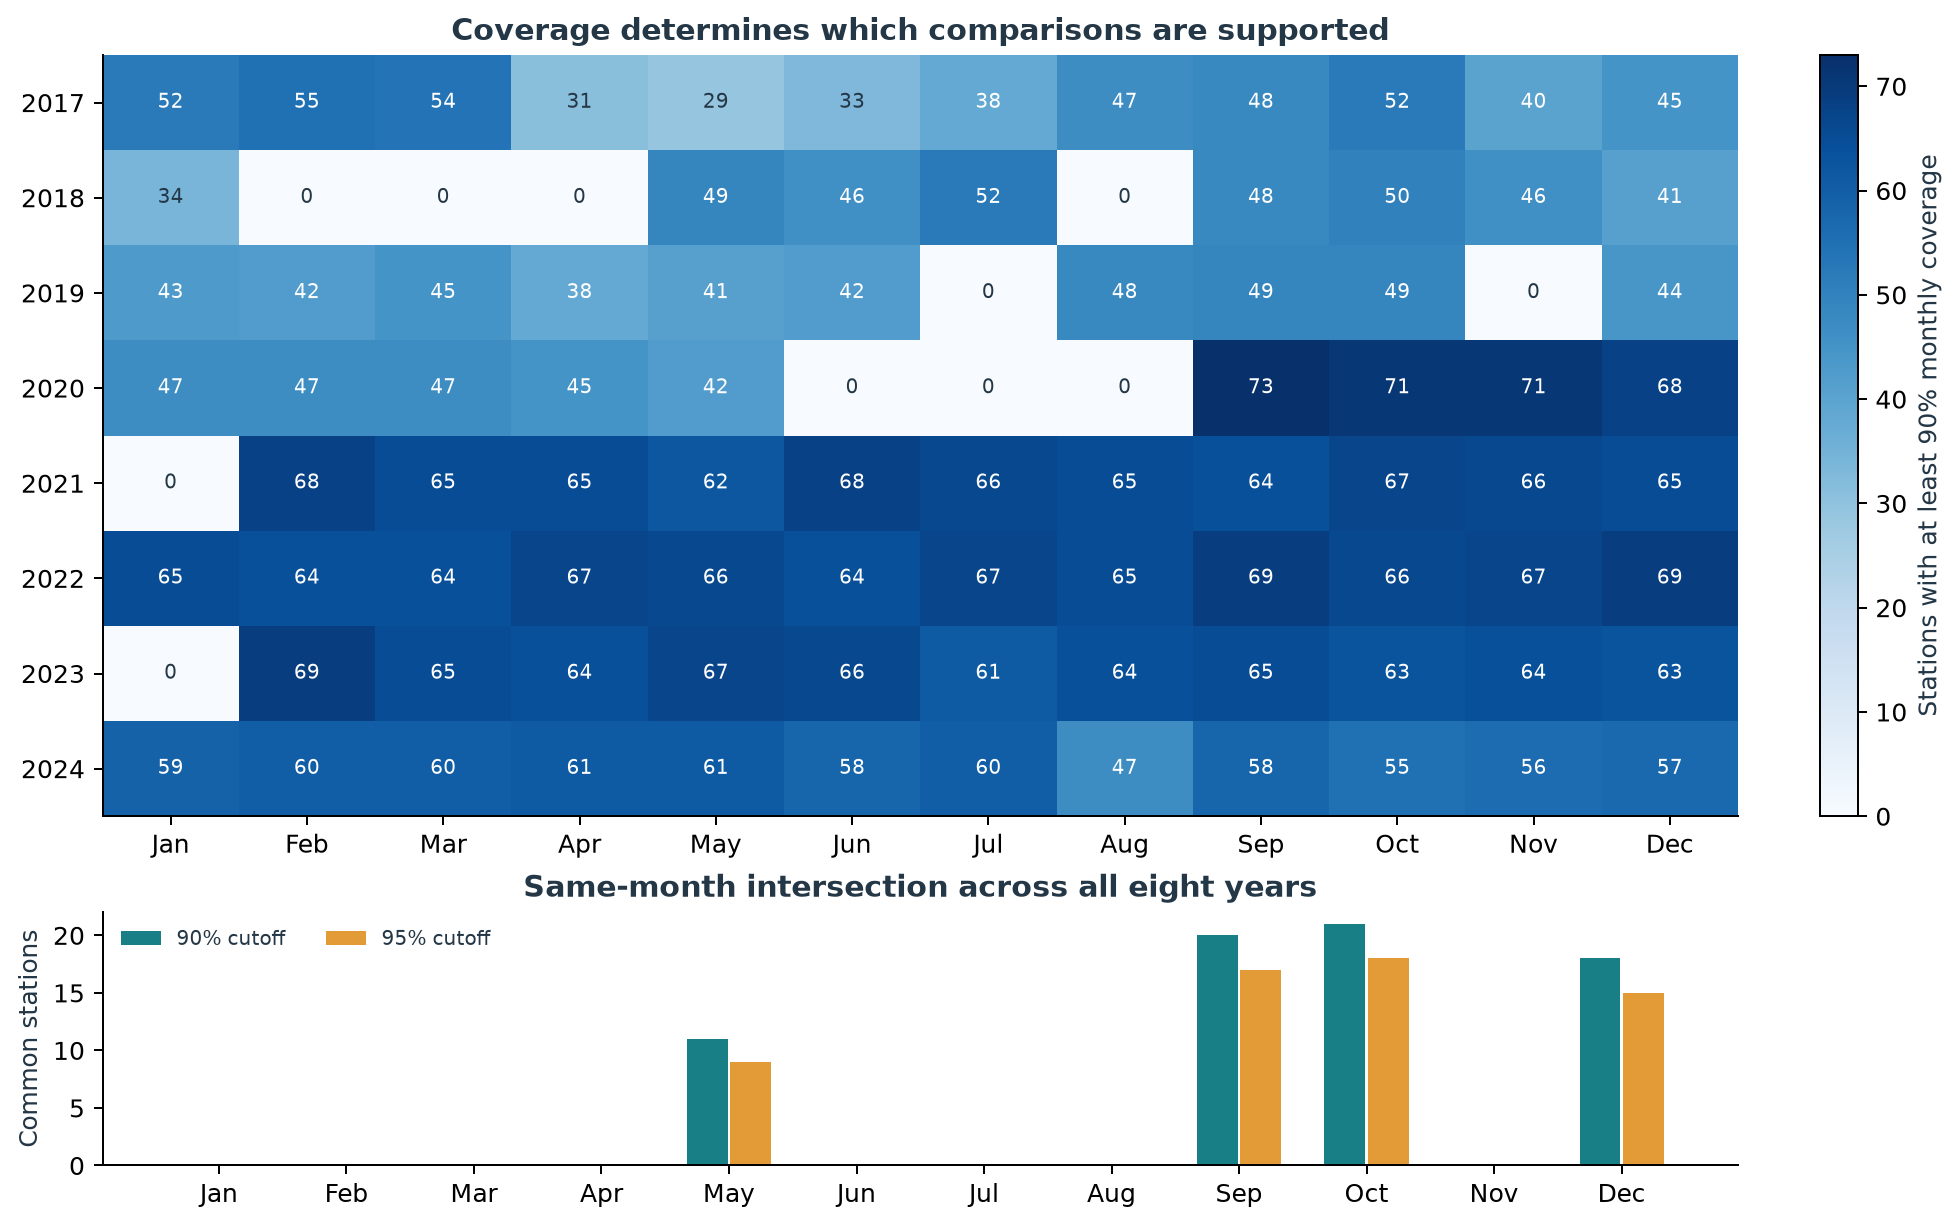

### 图2：月度降雨概览

观察哪些年月较湿或较干；不同格子的合格站点组成会变化。

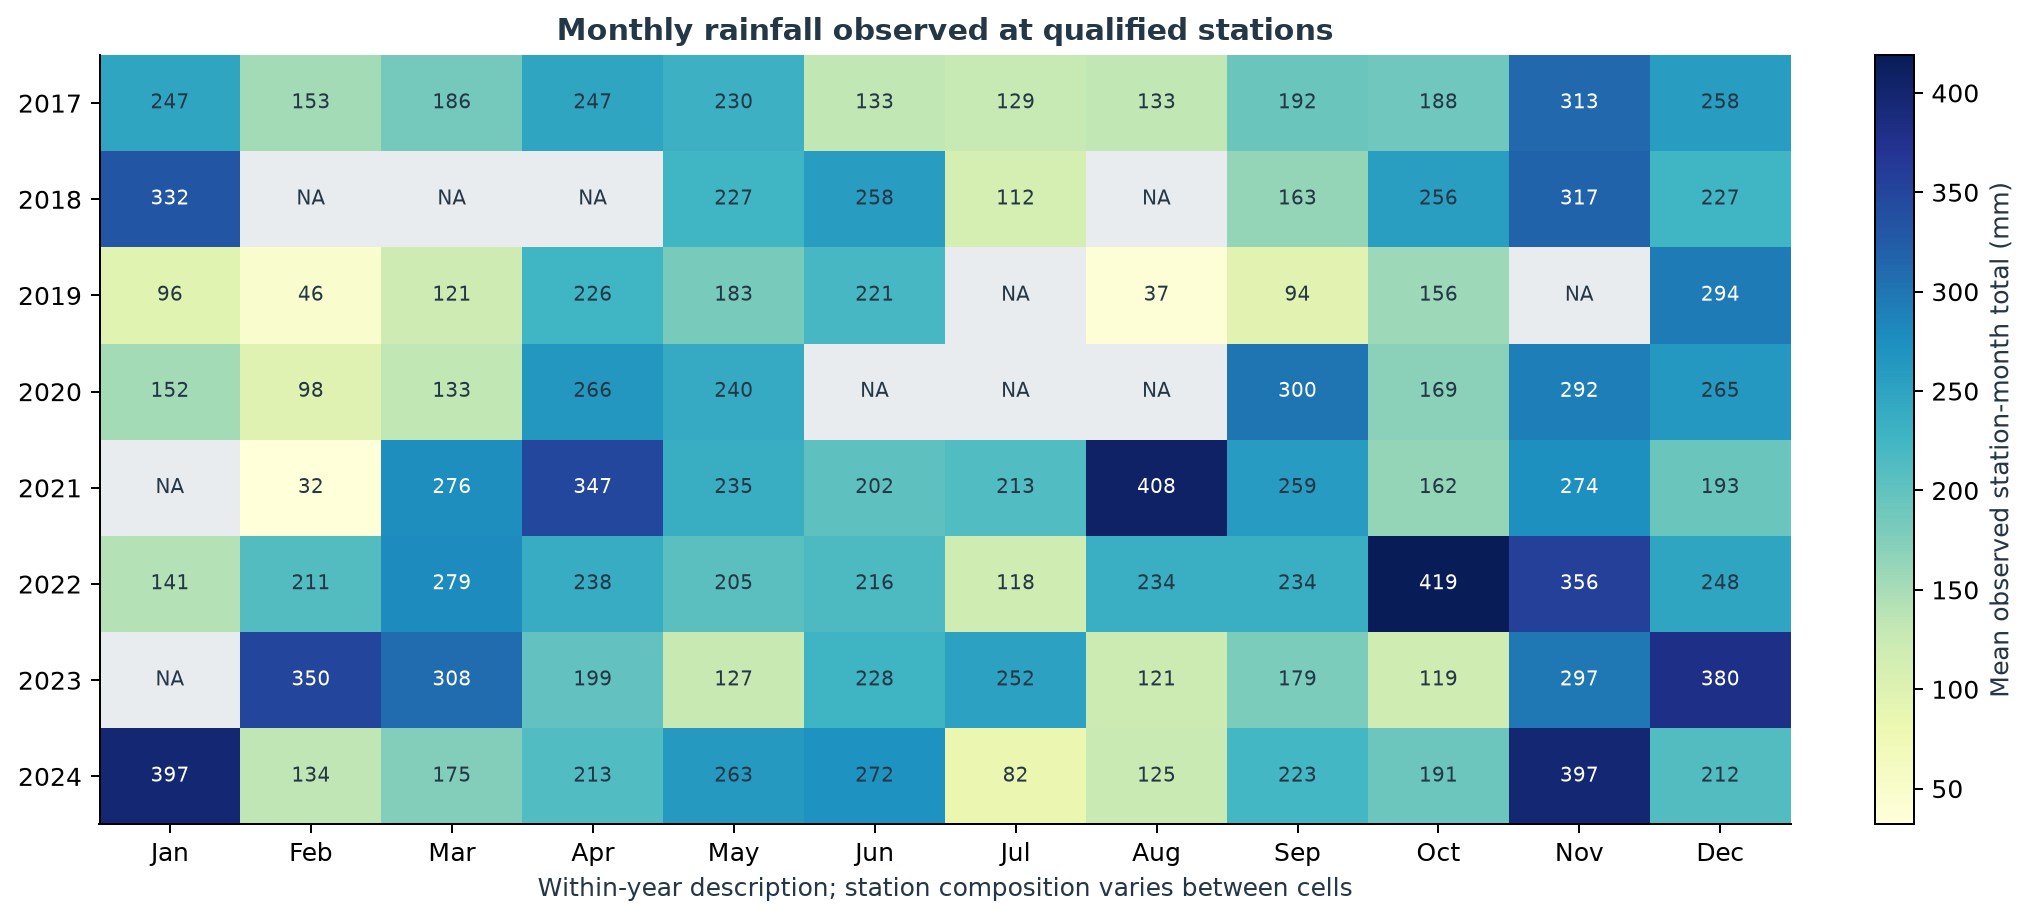

### 图3：降雨频率与非零强度

区分下雨更频繁与有雨时雨量更大；分位数是站点—月份条件分位数的平均。

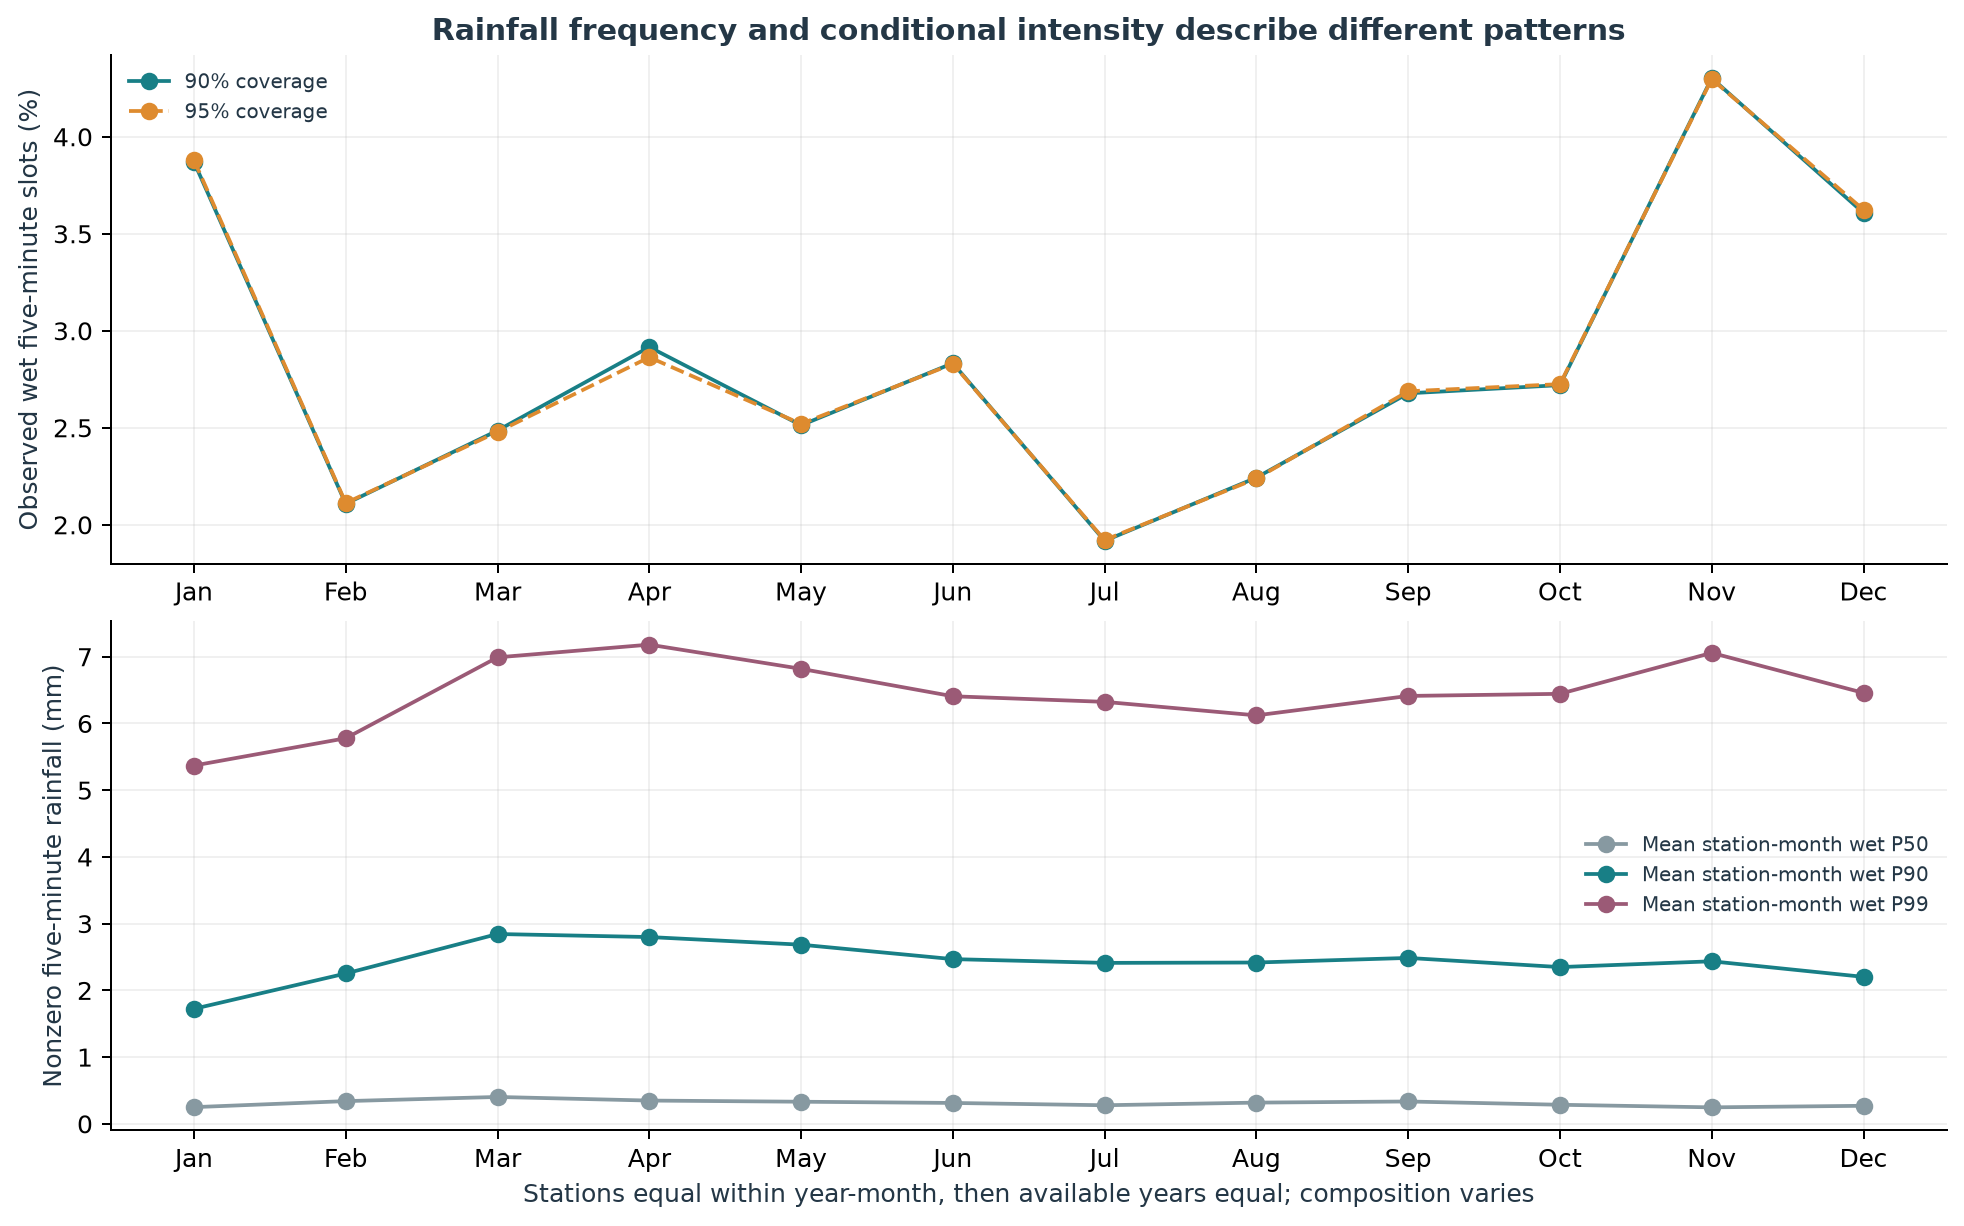

### 图4：小时降雨规律

比较一天各小时的有雨比例；以同一站点—月份的完整24小时覆盖控制站点组成。

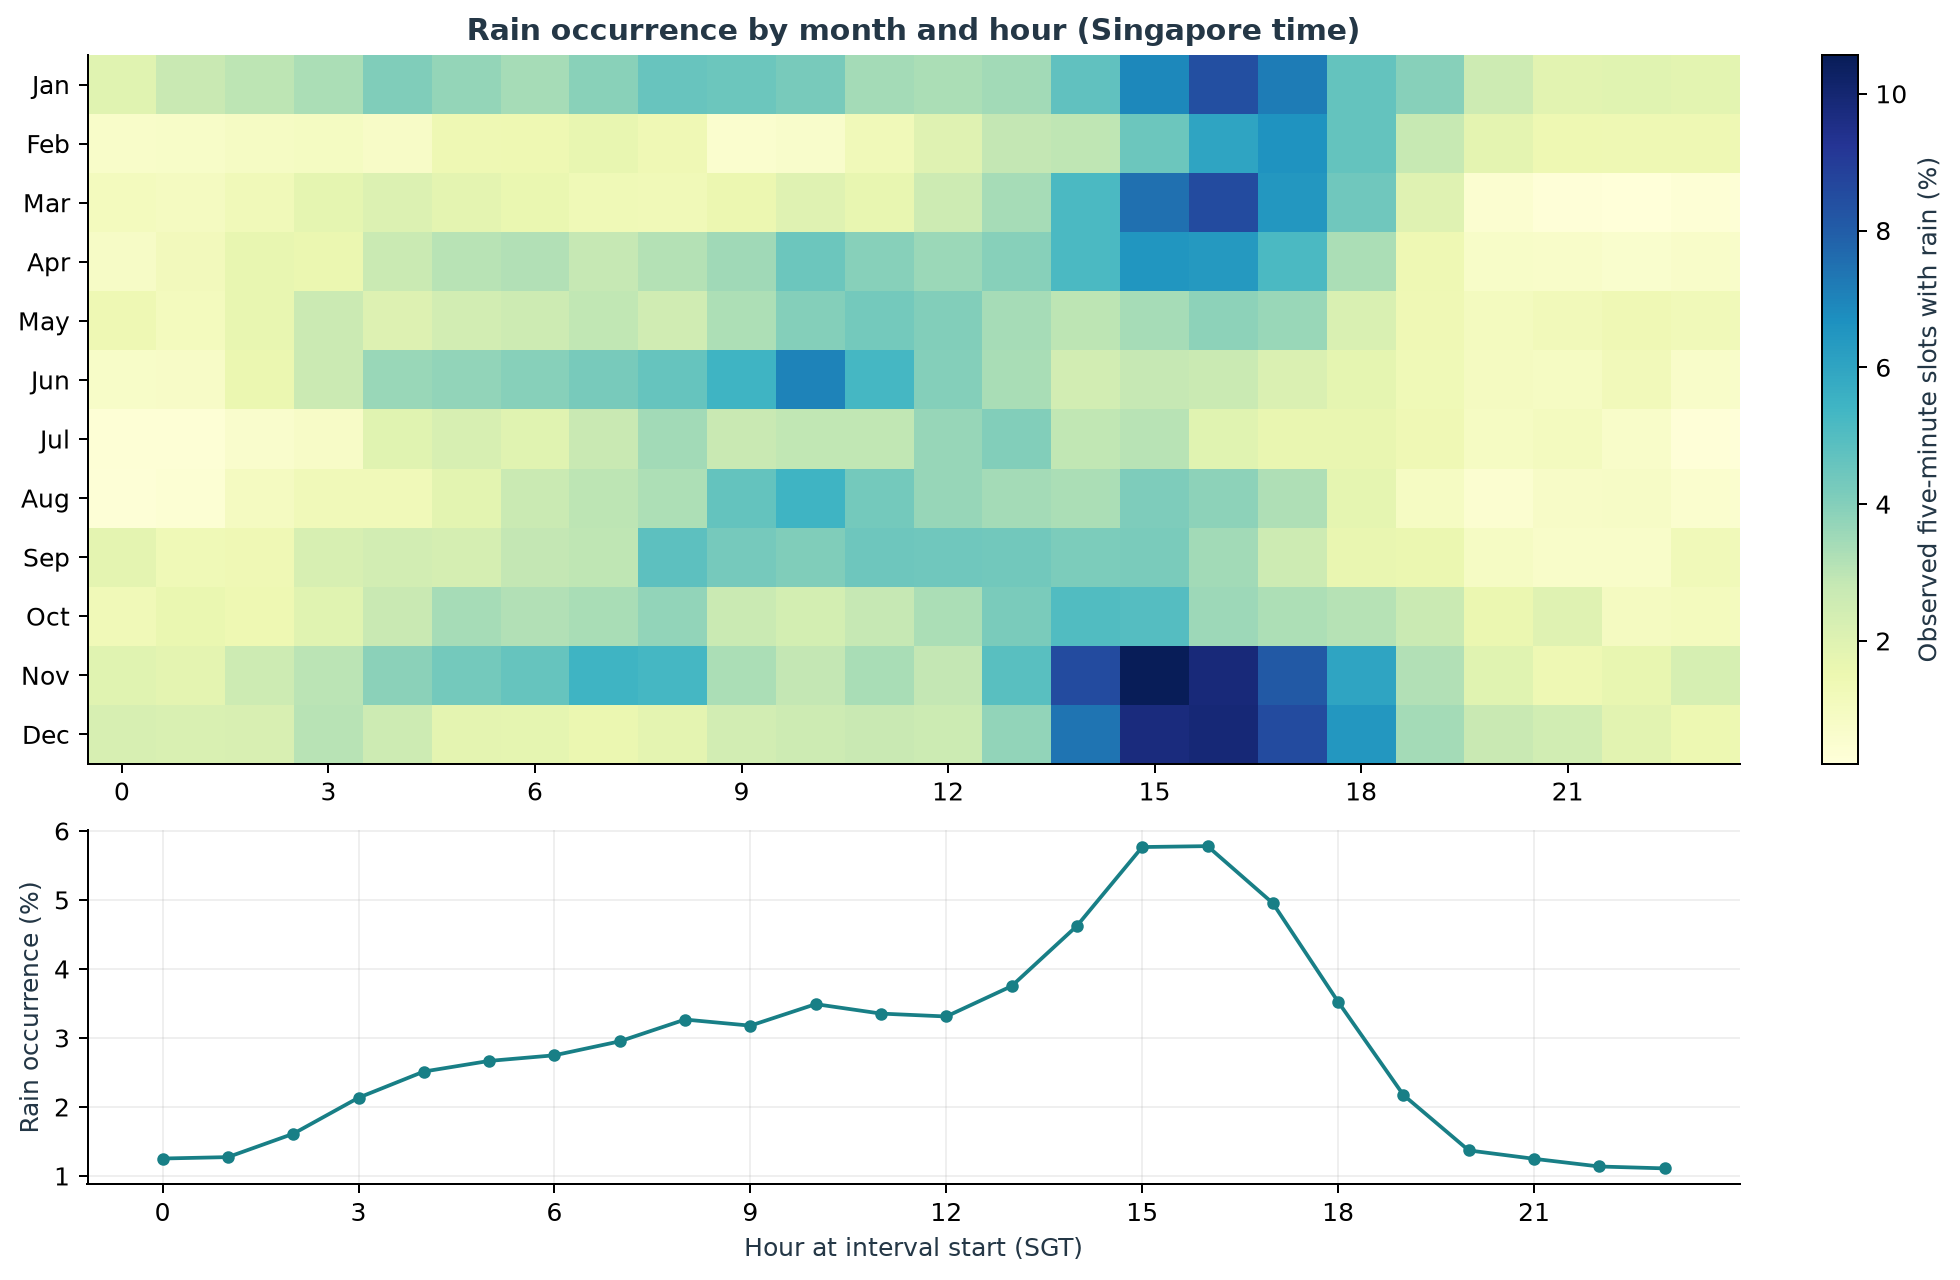

### 图5：年度概览与可比性限制

各年年度观测摘要使用不同合格站点；2018为NA，不能当作全国趋势。

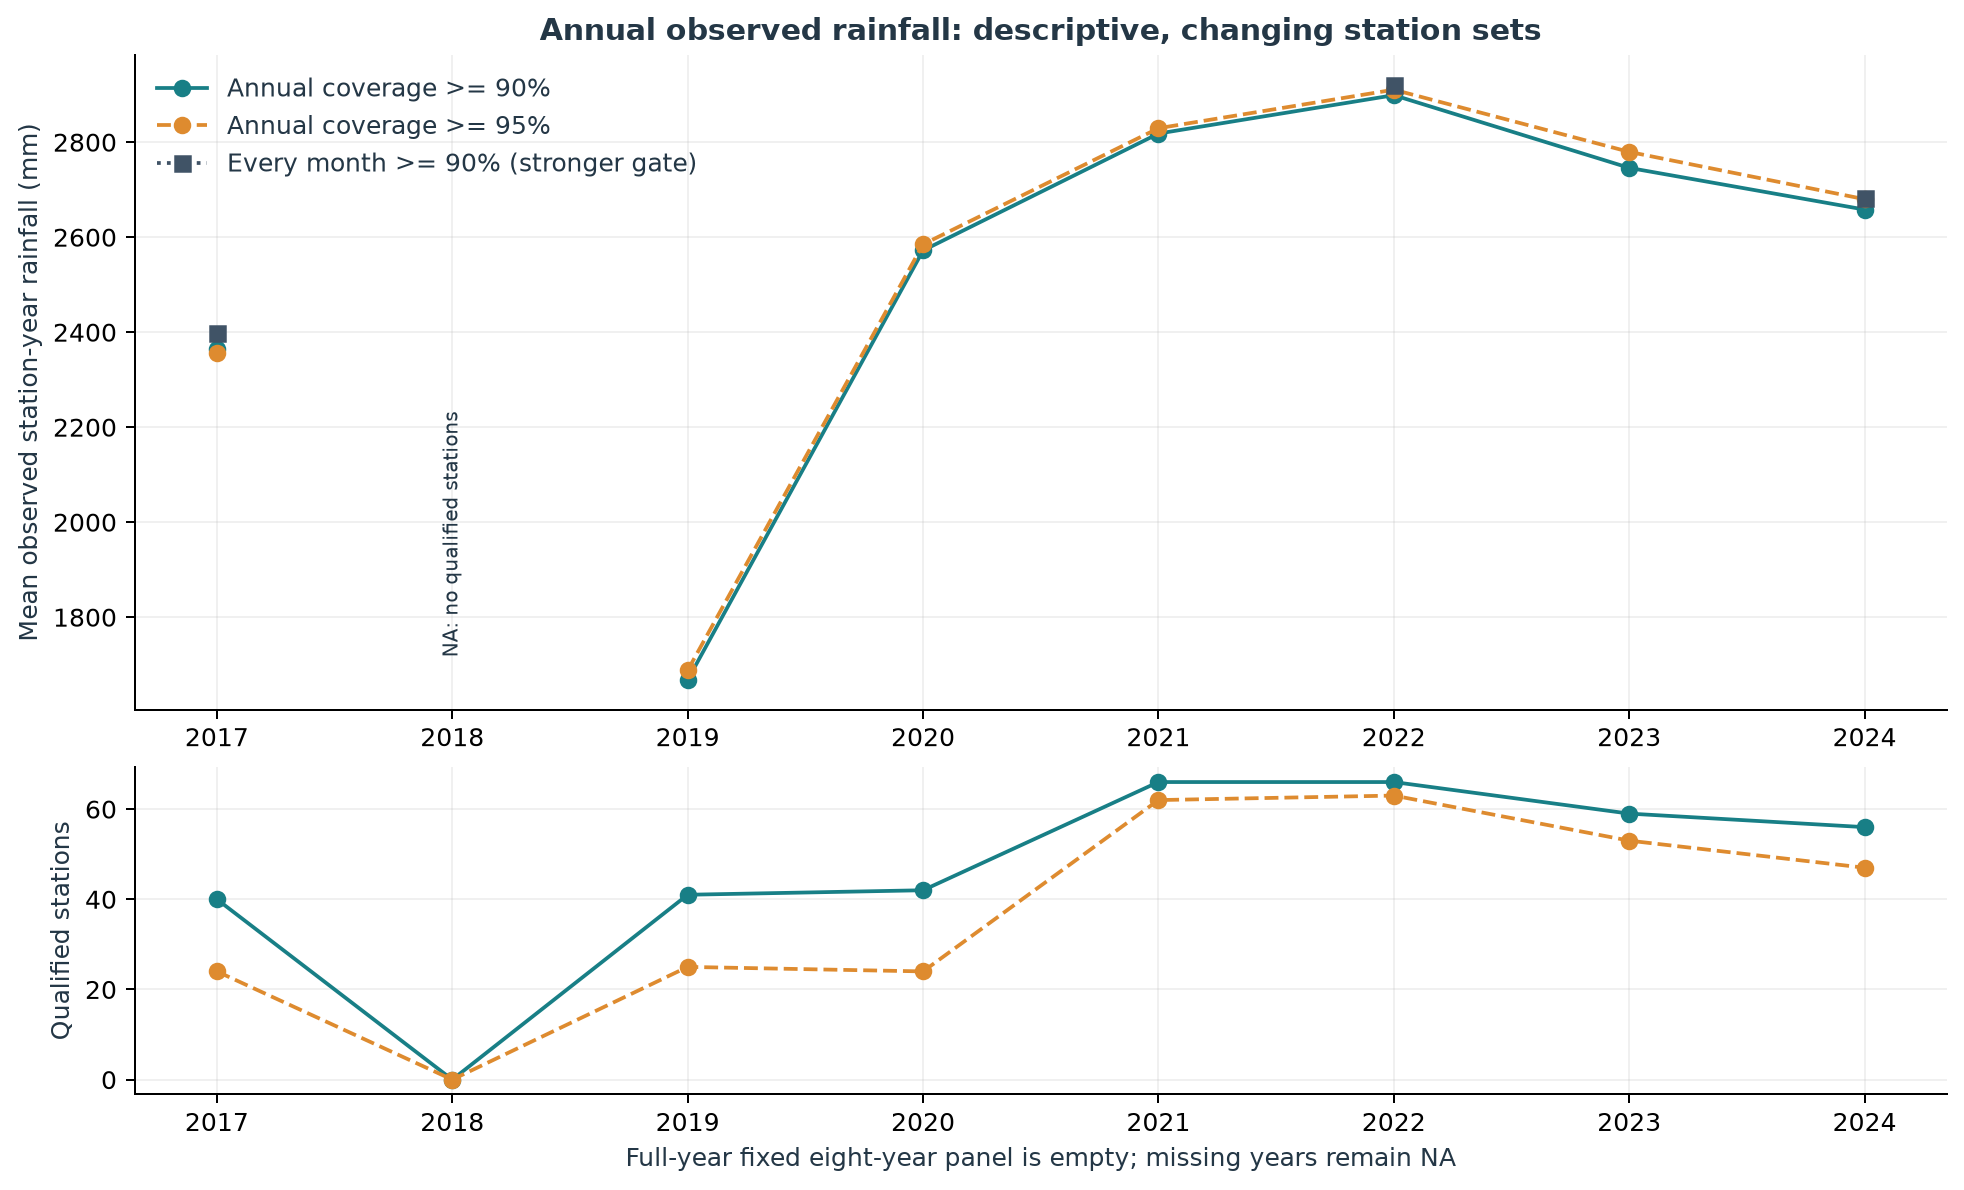

### 图6：严格八年同月比较

同月份固定八年共同站点，比较年际差异，并核对90%/95%覆盖门槛。

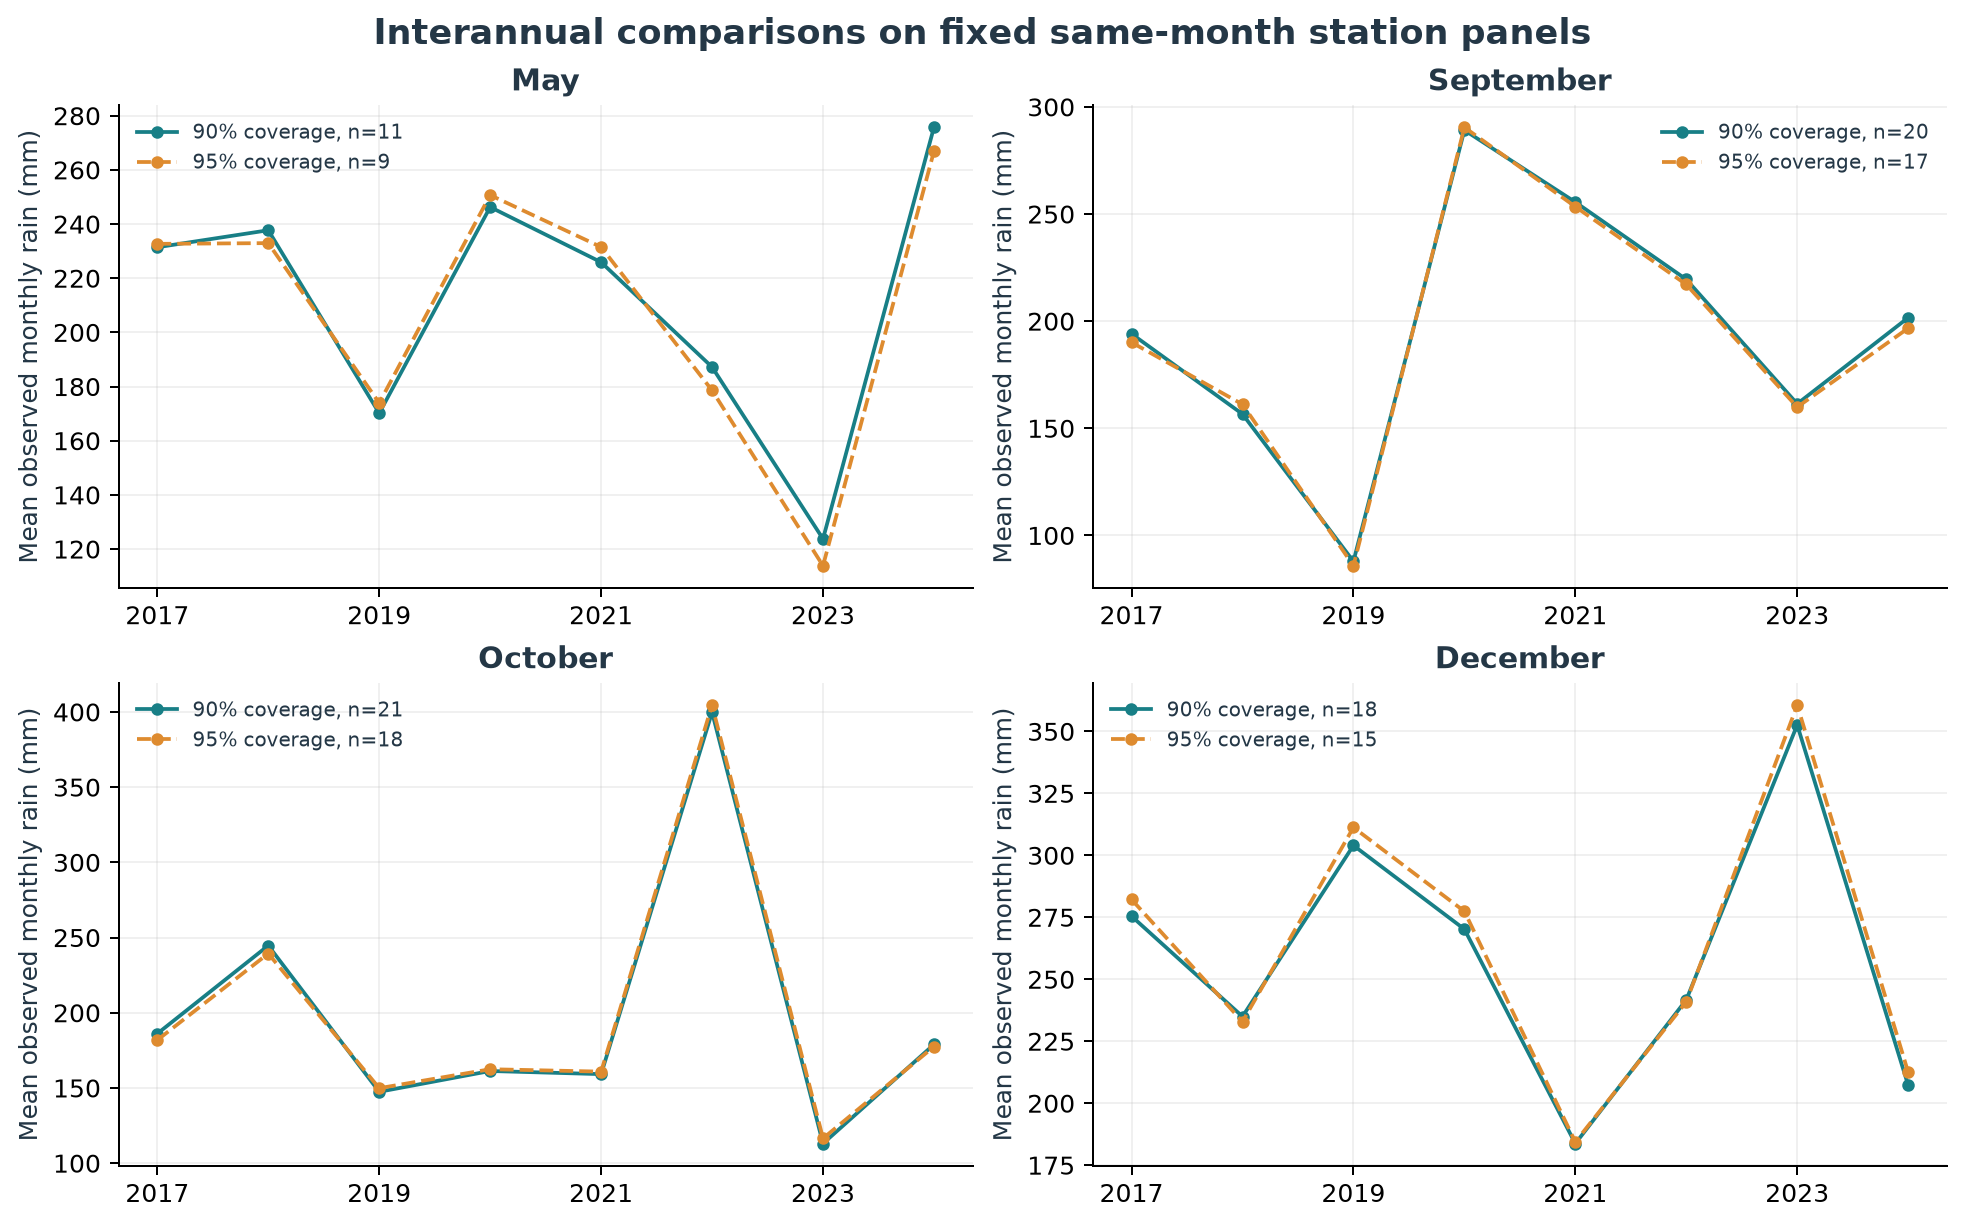

### 图7：相邻年份局部比较

每格使用相邻两年同月共同站点。后一年减前一年，n为站点数；不同格子不能串成长期趋势。

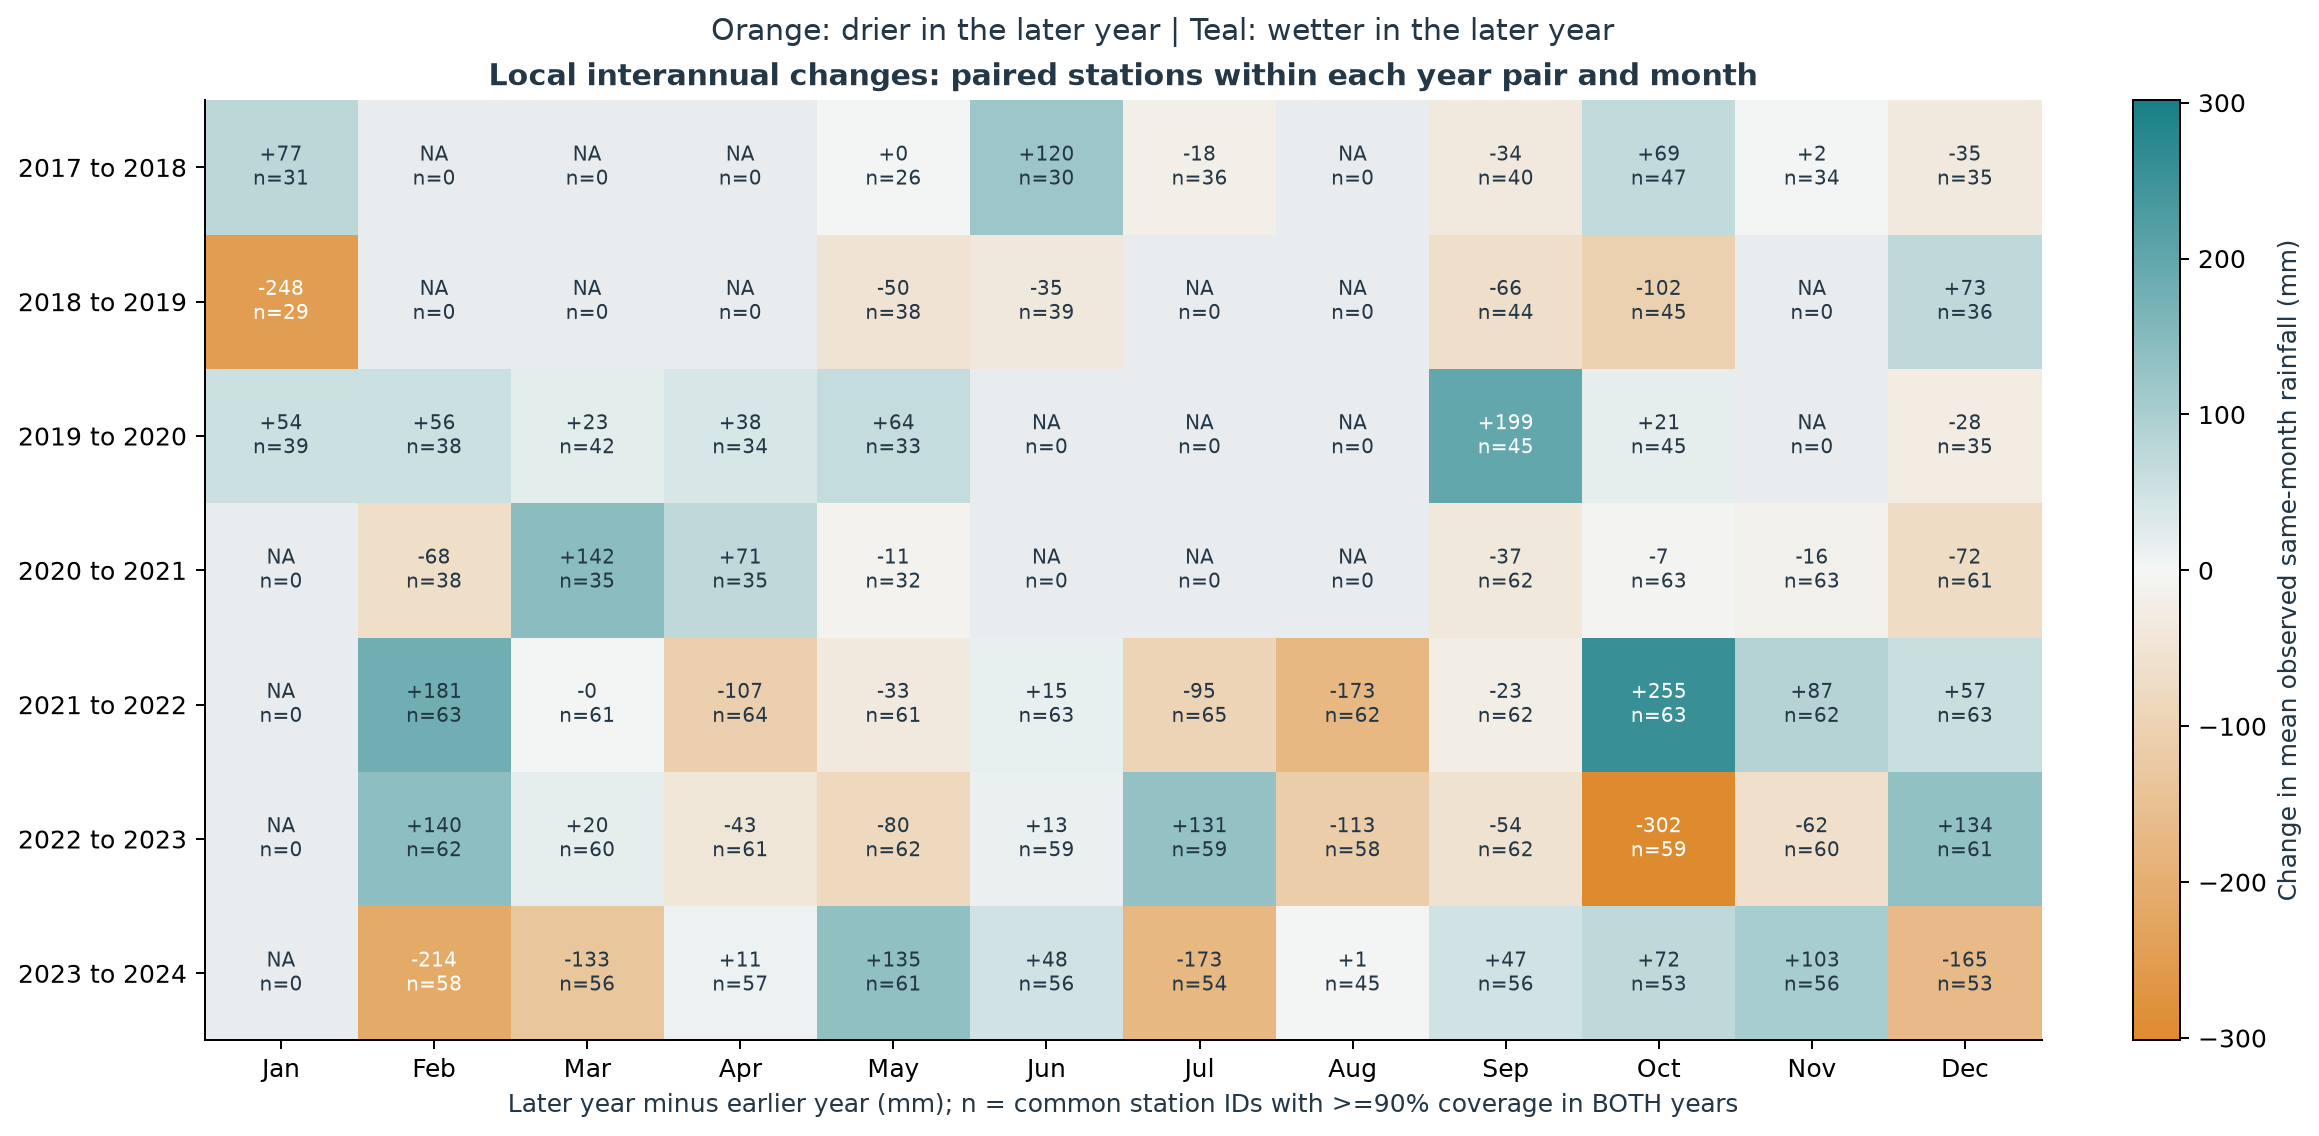

### 图8：同一面板的站点位置

十月21站与下一张柱状图完全相同。位置采用最新记录坐标；* S113有约39米坐标差，原因未知。

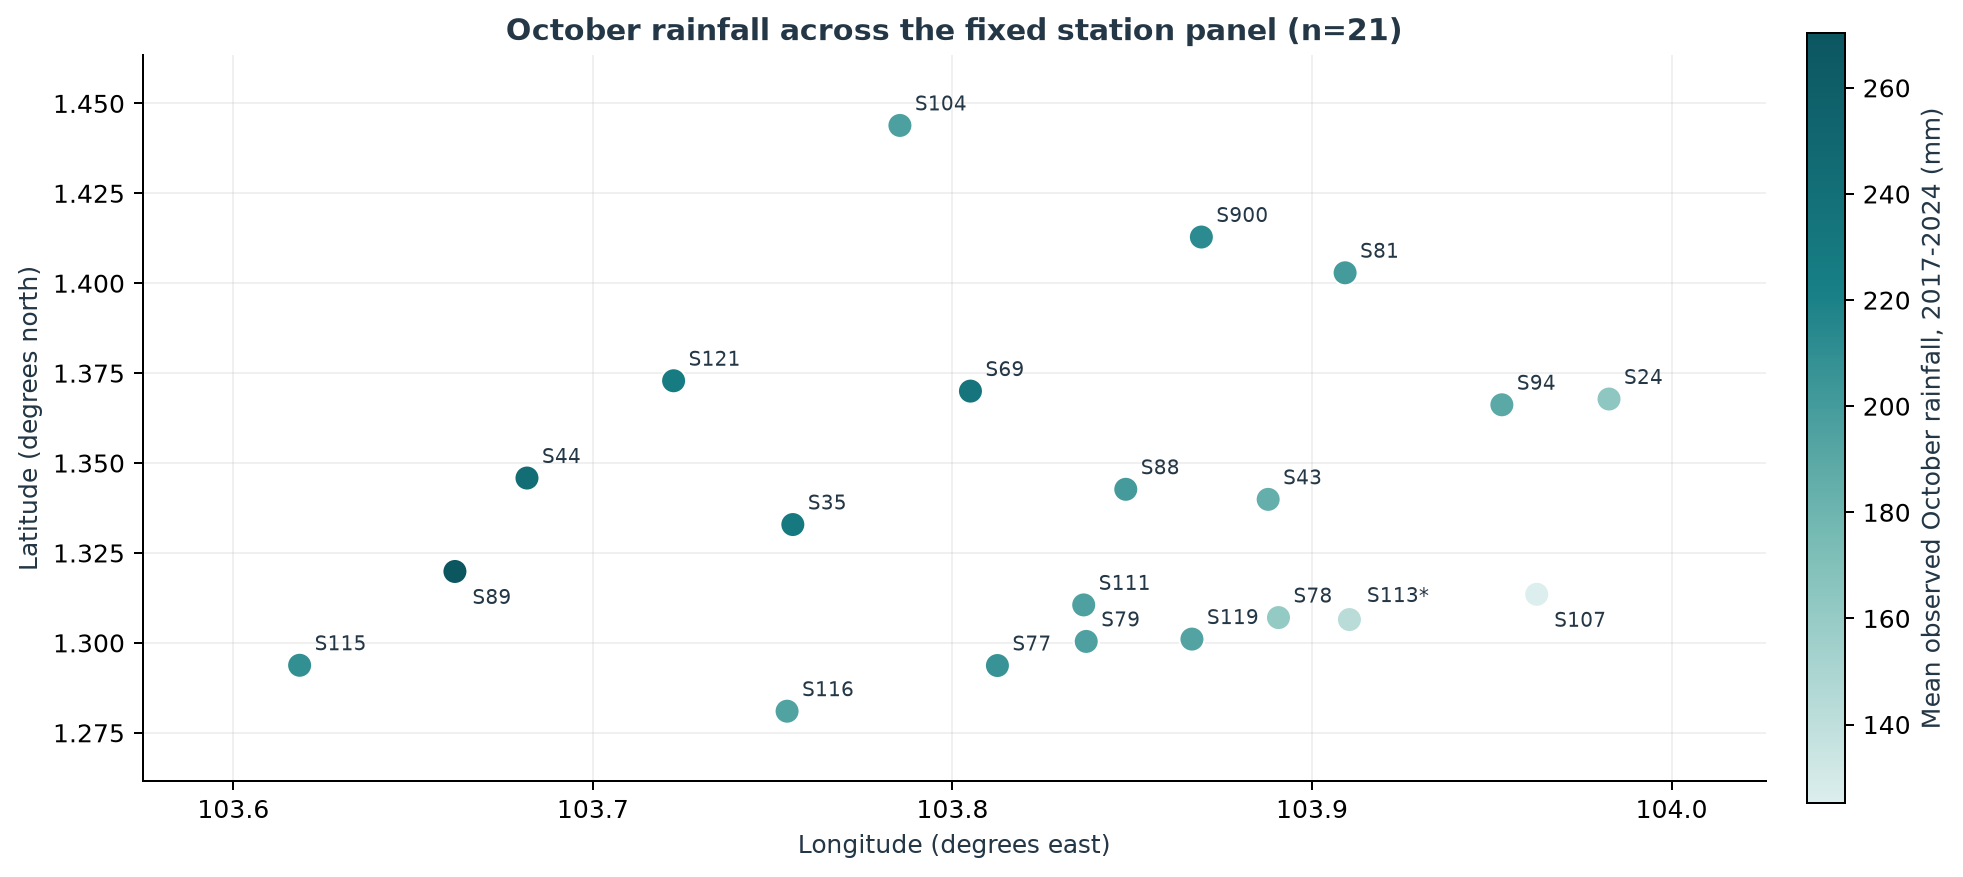

### 图9：同一面板的站点雨量差异

在地图认识位置之后，比较相同21站的十月雨量大小；不是全年站点排名。

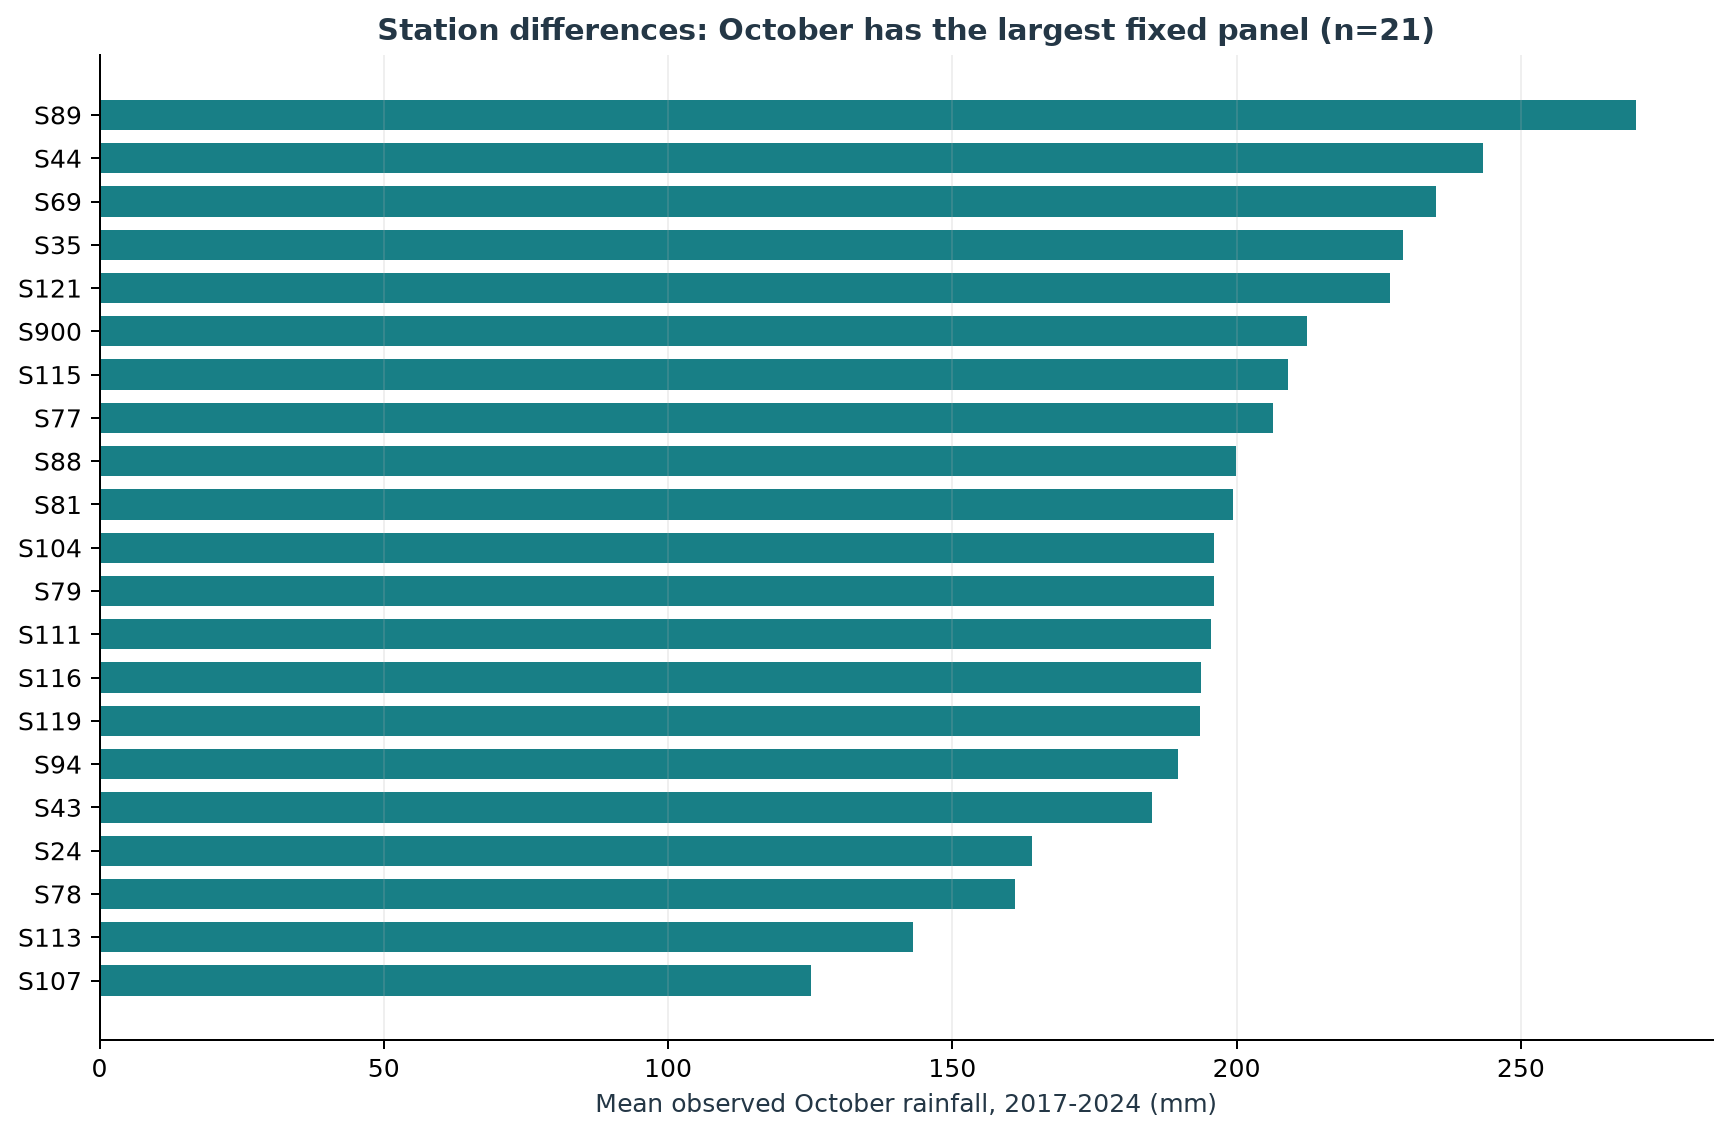

## 3. 参数开关

第一次保持 False。只改图表时，把 `REBUILD_PLOTS=True`；改了 Spark 汇总逻辑时，把两个开关都改为 True。重复实验请重新执行此格生成新输出目录。

In [57]:
RECOMPUTE_AGGREGATES = False
REBUILD_PLOTS = False
RUN_TAG = datetime.now().strftime('%Y%m%d_%H%M%S')
NEW_TASK1 = BROOT / 'results' / ('task1_notebook_' + RUN_TAG)
TASK1_INPUT = NEW_TASK1 if RECOMPUTE_AGGREGATES else EXISTING_TASK1
spark = None
print('原统计表：', TASK1_INPUT)
print('新结果目录：', NEW_TASK1)


原统计表： /Users/zhu/Documents/GitHub/DSA5208_Project2/B_delivery/results/task1_v2
新结果目录： /Users/zhu/Documents/GitHub/DSA5208_Project2/B_delivery/results/task1_notebook_20261013_211658


## 4. 启动全量 Spark（可选）

下面依次展示聚合、覆盖核对、小时统计和验证；只有开关为 True 才执行。

In [58]:
if RECOMPUTE_AGGREGATES:
    assert sys.version_info[:2] == (3, 11), '请使用项目 .venv 的 Python 3.11 内核'
    begin = time.monotonic()
    out = NEW_TASK1
    out.mkdir(parents=True, exist_ok=False)
    verification = d.verify_release(root, 'full')
    spark = start(root, 'B notebook Task 1')
else:
    print("已跳过。需要重跑时，在参数单元格把 RECOMPUTE_AGGREGATES 改成 True，再从该部分第一格按顺序运行。")


已跳过。需要重跑时，在参数单元格把 RECOMPUTE_AGGREGATES 改成 True，再从该部分第一格按顺序运行。


## 5. 月度聚合与 A 的覆盖表核对

In [59]:
if RECOMPUTE_AGGREGATES:
    from pyspark.sql import functions as F
    obs=d.read_tables(spark,root,'full',verify=False)['observations'].select(
        'station_id','rain_period_start_ts','rain_mm','rain_decimal_mm')
    x=(obs.withColumn('rain_year',F.year('rain_period_start_ts'))
        .withColumn('rain_month',F.month('rain_period_start_ts'))
        .withColumn('rain_hour',F.hour('rain_period_start_ts'))
        .filter(F.col('rain_year').between(2017,2024)))
    log('Aggregating station-month rainfall and nonzero intensity percentiles')
    monthly=(x.groupBy('rain_year','rain_month','station_id').agg(
        F.count('*').alias('observed_slots'),F.sum('rain_decimal_mm').alias('observed_rain_mm'),
        F.sum((F.col('rain_mm')>0).cast('long')).alias('wet_slots'),F.max('rain_mm').alias('max_5m_mm'),
        F.expr('percentile_approx(CASE WHEN rain_mm > 0 THEN rain_mm END, array(0.5,0.9,0.99), 1000)').alias('wet_quantiles')))
    monthly_rows=[]
    for r in monthly.toLocalIterator():
        q=r['wet_quantiles'] or [None,None,None]
        monthly_rows.append({'year':r['rain_year'],'month':r['rain_month'],'station_id':r['station_id'],
            'observed_slots':r['observed_slots'],'observed_rain_mm':str(r['observed_rain_mm']),
            'wet_slots':r['wet_slots'],'max_5m_mm':r['max_5m_mm'],
            'wet_p50_5m_mm':q[0],'wet_p90_5m_mm':q[1],'wet_p99_5m_mm':q[2]})
    reference=root/'outputs/p0_3_clean/p0_3_v1'
    coverage=rows(reference/'station_month_rain_period_coverage.csv')
    lookup={(r['year'],r['station_id'],r['month']):r for r in monthly_rows}
    checked=0
    for r in coverage:
        key=(int(r['year']),r['station_id'],int(r['month'])); actual=lookup.get(key)
        assert (actual['observed_slots'] if actual else 0)==int(r['observed_slots']),key
        if actual:
            assert abs(Decimal(actual['observed_rain_mm'])-Decimal(r['observed_rain_mm']))<Decimal('0.0000001'),key
            actual['calendar_slots']=int(r['calendar_slots']);actual['coverage']=float(r['coverage'])
            actual['wet_fraction_observed']=actual['wet_slots']/actual['observed_slots']
            actual['mean_5m_mm_observed']=float(actual['observed_rain_mm'])/actual['observed_slots']
        checked+=1
    assert len(lookup)==sum(int(r['observed_slots'])>0 for r in coverage)
    monthly_rows.sort(key=lambda r:(r['year'],r['month'],r['station_id']))
    csv_write(out/'station_month_metrics.csv',monthly_rows)
    csv_write(out/'coverage_calendar.csv',coverage)
    panel=rows(reference/'task1_comparable_month_station_panel.csv')
    csv_write(out/'strict_panel_membership.csv',panel)
else:
    print("已跳过。需要重跑时，在参数单元格把 RECOMPUTE_AGGREGATES 改成 True，再从该部分第一格按顺序运行。")


已跳过。需要重跑时，在参数单元格把 RECOMPUTE_AGGREGATES 改成 True，再从该部分第一格按顺序运行。


## 6. 小时聚合

In [60]:
if RECOMPUTE_AGGREGATES:
    log('Aggregating station-month-hour patterns; collecting summaries only')
    hourly=x.groupBy('rain_year','rain_month','rain_hour','station_id').agg(
        F.count('*').alias('observed_slots'),F.sum('rain_decimal_mm').alias('observed_rain_mm'),
        F.sum((F.col('rain_mm')>0).cast('long')).alias('wet_slots'))
    def hourly_records():
        for r in hourly.toLocalIterator():
            yield {'year':r['rain_year'],'month':r['rain_month'],'hour':r['rain_hour'],'station_id':r['station_id'],
                'observed_slots':r['observed_slots'],'observed_rain_mm':str(r['observed_rain_mm']),'wet_slots':r['wet_slots']}
    csv_write(out/'station_month_hour_metrics.csv',hourly_records(),
        ['year','month','hour','station_id','observed_slots','observed_rain_mm','wet_slots'])
else:
    print("已跳过。需要重跑时，在参数单元格把 RECOMPUTE_AGGREGATES 改成 True，再从该部分第一格按顺序运行。")


已跳过。需要重跑时，在参数单元格把 RECOMPUTE_AGGREGATES 改成 True，再从该部分第一格按顺序运行。


## 7. 网络日覆盖、验证与版本记录

In [61]:
if RECOMPUTE_AGGREGATES:
    log('Measuring network dates and individual missing-day coverage')
    daily=x.groupBy(F.to_date('rain_period_start_ts').alias('rain_date')).agg(
        F.count('*').alias('observed_slots'),F.countDistinct('station_id').alias('observed_stations'))
    daily_rows=[r.asDict() for r in daily.collect()]
    csv_write(out/'network_daily_coverage.csv',sorted(daily_rows,key=lambda r:r['rain_date']))
    elapsed=time.monotonic()-begin
    dump(out/'validation.json',{'status':'PASS','coverage_reference_rows_checked':checked,
        'station_months_with_observations':len(lookup),'calendar_observation_rows':sum(r['observed_slots'] for r in monthly_rows),
        'rainfall_sums_match_A_interval_calendar':True,'count_match_A_interval_calendar':True,
        'input_integrity':verification})
    metadata(root,out,'python src/B_task1_analysis.py --root PROJECT_ROOT',elapsed)
    log(f'Task 1 aggregates PASS; {elapsed:.1f}s')
else:
    print("已跳过。需要重跑时，在参数单元格把 RECOMPUTE_AGGREGATES 改成 True，再从该部分第一格按顺序运行。")


已跳过。需要重跑时，在参数单元格把 RECOMPUTE_AGGREGATES 改成 True，再从该部分第一格按顺序运行。


## 8. 关闭 Spark

全量计算完成或中途报错后都可以执行此格，释放 JVM 内存。

In [62]:
if spark is not None:
    spark.stop()
    spark = None
    print('Spark 已关闭')


## 9. 绘图依赖

如果只阅读已有结果可以跳过。启用绘图前执行一次下面这行；安装到当前 Notebook 的内核环境。

In [63]:
# 需要重新绘图时，删除下一行开头的 # 再运行。
# %pip install 'matplotlib>=3.8,<4'


## 10. 绘图初始化

原始汇总表复制到新结果目录，后续图表和来源表均写入新目录。下方每个图的实际计算和样式代码均可编辑。

In [64]:
if REBUILD_PLOTS:
    import numpy as np
    import matplotlib.pyplot as plt
    YEARS = list(range(2017, 2025))
    MONTHS = list(range(1, 13))
    def avg(values):
        values = list(values)
        return sum(values)/len(values) if values else None
    out = NEW_TASK1
    out.mkdir(parents=True, exist_ok=True)
    for filename in ['station_month_metrics.csv', 'coverage_calendar.csv', 'strict_panel_membership.csv', 'station_month_hour_metrics.csv', 'network_daily_coverage.csv']:
        source = TASK1_INPUT / filename
        target = out / filename
        if source.resolve() != target.resolve():
            shutil.copy2(source, target)
    fig = out / 'figures'
    fig.mkdir(exist_ok=True)
else:
    print("已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。")


已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。


## 11. 指标计算与图表样式

In [65]:
if REBUILD_PLOTS:
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,'axes.spines.top':False,'axes.spines.right':False,
        'axes.titleweight':'bold','figure.dpi':130,'savefig.dpi':180,'axes.labelcolor':'#243746','text.color':'#243746'})
    def save(name):
        plt.savefig(fig/(name+'.png'),bbox_inches='tight',facecolor='white')
        plt.savefig(fig/(name+'.pdf'),bbox_inches='tight',facecolor='white');plt.close()
    monthly=rows(out/'station_month_metrics.csv')
    for r in monthly:
        for k in ['year','month','observed_slots','wet_slots']:r[k]=int(r[k])
        for k in ['coverage','observed_rain_mm','wet_fraction_observed','mean_5m_mm_observed','max_5m_mm']:
            r[k]=float(r[k])
    lookup={(r['year'],r['month'],r['station_id']):r for r in monthly}
    cover=rows(out/'coverage_calendar.csv')
    panel=rows(out/'strict_panel_membership.csv')
    strict=[]
    for p in panel:
        cutoff=float(p['coverage_cutoff']);m=int(p['month']);ids=p['station_ids'].split('|') if p['station_ids'] else []
        for y in YEARS:
            selected=[lookup[(y,m,s)] for s in ids]
            strict.append({'coverage_cutoff':cutoff,'year':y,'month':m,'n_stations':len(selected),
                'mean_station_month_observed_mm':avg(r['observed_rain_mm'] for r in selected),
                'mean_station_wet_fraction':avg(r['wet_fraction_observed'] for r in selected)})
    csv_write(out/'strict_same_month_summary.csv',strict)
    descriptive=[]
    for cutoff in [.9,.95]:
        for y in YEARS:
            for m in MONTHS:
                selected=[r for r in monthly if r['year']==y and r['month']==m and r['coverage']>=cutoff]
                descriptive.append({'coverage_cutoff':cutoff,'year':y,'month':m,'n_stations':len(selected),
                    'mean_station_month_observed_mm':avg(r['observed_rain_mm'] for r in selected),
                    'mean_station_wet_fraction':avg(r['wet_fraction_observed'] for r in selected)})
    csv_write(out/'descriptive_year_month_summary.csv',descriptive)
else:
    print("已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。")


已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。


## 12. 图1：数据覆盖


In [66]:
if REBUILD_PLOTS:
    # Exposure and station-panel availability are displayed before rainfall comparisons.
    grid=np.full((8,12),np.nan)
    coverage_summary=[]
    for y in YEARS:
        for m in MONTHS:
            rr=[r for r in cover if int(r['year'])==y and int(r['month'])==m]
            n=sum(float(r['coverage'])>=.9 for r in rr)
            grid[y-2017,m-1]=n
            coverage_summary.append({'year':y,'month':m,'available_station_ids':len(rr),'qualified_90pct':n,
                'network_observed_slots':sum(int(r['observed_slots']) for r in rr)})
    csv_write(out/'coverage_figure_source.csv',coverage_summary)
    f,ax=plt.subplots(2,1,figsize=(10.8,6.7),gridspec_kw={'height_ratios':[3,1]},layout='constrained')
    im=ax[0].imshow(grid,aspect='auto',cmap='Blues',vmin=0)
    ax[0].set(xticks=range(12),xticklabels=[calendar.month_abbr[m] for m in MONTHS],yticks=range(8),yticklabels=YEARS,
        title='Coverage determines which comparisons are supported')
    for iy in range(8):
        for ix in range(12):ax[0].text(ix,iy,str(int(grid[iy,ix])),ha='center',va='center',fontsize=8,color='white' if grid[iy,ix]>35 else '#243746')
    f.colorbar(im,ax=ax[0],label='Stations with at least 90% monthly coverage')
    for cutoff,color,offset in [(.9,'#187f86',-.17),(.95,'#e39b38',.17)]:
        counts=[next(int(p['comparable_station_count']) for p in panel if float(p['coverage_cutoff'])==cutoff and int(p['month'])==m) for m in MONTHS]
        ax[1].bar(np.arange(12)+offset,counts,width=.32,label=f'{cutoff:.0%} cutoff',color=color)
    ax[1].set(xticks=range(12),xticklabels=[calendar.month_abbr[m] for m in MONTHS],ylabel='Common stations',title='Same-month intersection across all eight years')
    ax[1].legend(frameon=False,ncol=2,fontsize=8);save('01_coverage_and_panel')
else:
    print("已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。")


已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。


## 13. 图2：月度降雨


In [67]:
if REBUILD_PLOTS:
    # Descriptive eight-year seasonal picture: no unsupported fixed-panel inference.
    g=np.full((8,12),np.nan)
    for r in descriptive:
        if r['coverage_cutoff']==.9 and r['mean_station_month_observed_mm'] is not None:g[r['year']-2017,r['month']-1]=r['mean_station_month_observed_mm']
    f,ax=plt.subplots(figsize=(11.2,5),layout='constrained')
    cm=plt.get_cmap('YlGnBu').copy();cm.set_bad('#e9ecef')
    im=ax.imshow(g,aspect='auto',cmap=cm)
    ax.set(xticks=range(12),xticklabels=[calendar.month_abbr[m] for m in MONTHS],yticks=range(8),yticklabels=YEARS,
        title='Monthly rainfall observed at qualified stations',xlabel='Within-year description; station composition varies between cells')
    for iy in range(8):
        for ix in range(12):
            v=g[iy,ix]
            ax.text(ix,iy,'NA' if np.isnan(v) else f'{v:.0f}',ha='center',va='center',fontsize=8,
                color='white' if np.isfinite(v) and v>np.nanmax(g)*.65 else '#243746')
    f.colorbar(im,ax=ax,label='Mean observed station-month total (mm)');save('02_descriptive_monthly_rainfall')
else:
    print("已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。")


已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。


## 14. 图3：频率与非零强度


In [68]:
if REBUILD_PLOTS:
    # Rain occurrence versus nonzero intensity; averages of station quantiles, not pooled quantiles.
    frequency_year_month=[]
    for cutoff in [.9,.95]:
        for y in YEARS:
            for m in MONTHS:
                selected=[r for r in monthly if r['year']==y and r['month']==m and r['coverage']>=cutoff]
                metric={'coverage_cutoff':cutoff,'year':y,'month':m,'n_stations':len(selected),
                    'wet_fraction':avg(r['wet_fraction_observed'] for r in selected)}
                for q in ['p50','p90','p99']:
                    vv=[float(r[f'wet_{q}_5m_mm']) for r in selected if r[f'wet_{q}_5m_mm'] not in ['',None]]
                    metric[f'mean_station_wet_{q}_5m_mm']=avg(vv)
                    metric[f'n_stations_wet_{q}']=len(vv)
                frequency_year_month.append(metric)
    csv_write(out/'frequency_intensity_year_month.csv',frequency_year_month)
    frequency_summary=[]
    for cutoff in [.9,.95]:
        for m in MONTHS:
            rr=[r for r in frequency_year_month if r['coverage_cutoff']==cutoff and r['month']==m and r['n_stations']>0]
            metric={'coverage_cutoff':cutoff,'month':m,'available_years':len(rr),
                'wet_fraction':avg(r['wet_fraction'] for r in rr)}
            for q in ['p50','p90','p99']:
                values=[r[f'mean_station_wet_{q}_5m_mm'] for r in rr if r[f'mean_station_wet_{q}_5m_mm'] is not None]
                metric[f'mean_station_wet_{q}_5m_mm']=avg(values)
                metric[f'available_years_wet_{q}']=len(values)
            frequency_summary.append(metric)
    csv_write(out/'monthly_frequency_intensity_summary.csv',frequency_summary)
    f,ax=plt.subplots(2,1,figsize=(10.8,6.7),layout='constrained')
    for cutoff,color,style in [(.9,'#187f86','-'),(.95,'#de8b2f','--')]:
        rr=[r for r in frequency_summary if r['coverage_cutoff']==cutoff]
        ax[0].plot(MONTHS,[r['wet_fraction']*100 if r['wet_fraction'] is not None else np.nan for r in rr],
            style,marker='o',color=color,label=f'{cutoff:.0%} coverage')
    rr=[r for r in frequency_summary if r['coverage_cutoff']==.9]
    for q,color in [('p50','#8799a1'),('p90','#187f86'),('p99','#9b5a76')]:
        ax[1].plot(MONTHS,[r[f'mean_station_wet_{q}_5m_mm'] if r[f'mean_station_wet_{q}_5m_mm'] is not None else np.nan for r in rr],
            marker='o',color=color,label=f'Mean station-month wet {q.upper()}')
    for axis in ax:
        axis.set(xticks=MONTHS,xticklabels=[calendar.month_abbr[m] for m in MONTHS]);axis.grid(alpha=.18);axis.legend(frameon=False,fontsize=8)
    ax[0].set(title='Rainfall frequency and conditional intensity describe different patterns',ylabel='Observed wet five-minute slots (%)')
    ax[1].set(ylabel='Nonzero five-minute rainfall (mm)',xlabel='Stations equal within year-month, then available years equal; composition varies')
    save('07_frequency_and_intensity')
else:
    print("已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。")


已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。


## 15. 图4：小时降雨


In [69]:
if REBUILD_PLOTS:
    # Hourly rates: require >=90% coverage in ALL 24 hours for each station-month.
    hrows=rows(out/'station_month_hour_metrics.csv');hour_groups=collections.defaultdict(list)
    hour_coverage=collections.defaultdict(list)
    for r in hrows:
        y,m=int(r['year']),int(r['month'])
        hour_coverage[(y,m,r['station_id'])].append(int(r['observed_slots'])/(calendar.monthrange(y,m)[1]*12))
    balanced_station_months={key for key,v in hour_coverage.items()
        if len(v)==24 and min(v)>=.9 and lookup[key]['coverage']>=.9}
    for r in hrows:
        y,m,h=int(r['year']),int(r['month']),int(r['hour']);s=r['station_id'];n=int(r['observed_slots'])
        if (y,m,s) in balanced_station_months:
            hour_groups[(y,m,h)].append((int(r['wet_slots'])/n,float(r['observed_rain_mm'])/n))
    hourly=[]
    for (y,m,h),v in sorted(hour_groups.items()):hourly.append({'year':y,'month':m,'hour':h,'n_stations':len(v),
        'wet_fraction':avg(x[0] for x in v),'mean_observed_5m_mm':avg(x[1] for x in v)})
    csv_write(out/'hourly_qualified_year_month.csv',hourly)
    monthhour=[];hg=np.full((12,24),np.nan)
    for m in MONTHS:
        for h in range(24):
            rr=[r for r in hourly if r['month']==m and r['hour']==h]
            value=avg(r['wet_fraction'] for r in rr)
            monthhour.append({'month':m,'hour':h,'n_years':len(rr),'wet_fraction':value})
            if value is not None:hg[m-1,h]=value*100
    csv_write(out/'month_hour_figure_source.csv',monthhour)
    hourline=[{'hour':h,'n_year_months':len([r for r in hourly if r['hour']==h]),
        'wet_fraction':avg(r['wet_fraction'] for r in hourly if r['hour']==h)} for h in range(24)]
    csv_write(out/'hourly_profile_figure_source.csv',hourline)
    f,ax=plt.subplots(2,1,figsize=(10.8,7),layout='constrained',gridspec_kw={'height_ratios':[2,1]})
    im=ax[0].imshow(hg,aspect='auto',cmap='YlGnBu');ax[0].set(yticks=range(12),yticklabels=[calendar.month_abbr[m] for m in MONTHS],xticks=range(0,24,3),xticklabels=range(0,24,3),title='Rain occurrence by month and hour (Singapore time)')
    f.colorbar(im,ax=ax[0],label='Observed five-minute slots with rain (%)')
    ax[1].plot(range(24),[r['wet_fraction']*100 for r in hourline],color='#187f86',marker='o',ms=4)
    ax[1].set(xlabel='Hour at interval start (SGT)',ylabel='Rain occurrence (%)',xticks=range(0,24,3));ax[1].grid(alpha=.2)
    save('04_hourly_rain_occurrence')
else:
    print("已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。")


已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。


## 16. 图5：年度概览


In [70]:
if REBUILD_PLOTS:
    # Annual descriptive summary; no interpolation for unsupported years.
    annual_by_station = collections.defaultdict(list)
    for r in cover:
        annual_by_station[(int(r['year']),r['station_id'])].append(r)
    annual_station = []
    for (y,s),rr in sorted(annual_by_station.items()):
        slots = sum(int(r['observed_slots']) for r in rr)
        expected = sum(int(r['calendar_slots']) for r in rr)
        annual_station.append({'year':y,'station_id':s,'observed_slots':slots,
            'calendar_slots':expected,'annual_coverage':slots/expected,
            'minimum_month_coverage':min(float(r['coverage']) for r in rr),
            'months_ge_90pct':sum(float(r['coverage'])>=.9 for r in rr),
            'observed_annual_rain_mm':sum(float(r['observed_rain_mm']) for r in rr)})
    csv_write(out/'annual_station_coverage.csv',annual_station)
    annual_summary=[]; annual_fixed=[]
    for cutoff in [.9,.95]:
        selected_by_year={y:{r['station_id'] for r in annual_station if r['year']==y and r['annual_coverage']>=cutoff} for y in YEARS}
        fixed_ids=set.intersection(*(selected_by_year[y] for y in YEARS))
        for y in YEARS:
            selected=[r for r in annual_station if r['year']==y and r['station_id'] in selected_by_year[y]]
            fixed=[r for r in annual_station if r['year']==y and r['station_id'] in fixed_ids]
            annual_summary.append({'coverage_cutoff':cutoff,'year':y,'n_stations':len(selected),
                'mean_observed_annual_mm':avg(r['observed_annual_rain_mm'] for r in selected),
                'mean_annual_coverage':avg(r['annual_coverage'] for r in selected),
                'lowest_month_coverage':min((r['minimum_month_coverage'] for r in selected),default=None),
                'stations_passing_every_month':sum(r['minimum_month_coverage']>=cutoff for r in selected),
                'mean_observed_annual_mm_each_month':avg(r['observed_annual_rain_mm'] for r in selected if r['minimum_month_coverage']>=cutoff),
                'scope':'descriptive within-year annual coverage; station composition varies'})
            annual_fixed.append({'coverage_cutoff':cutoff,'year':y,'n_stations':len(fixed),
                'mean_observed_annual_mm':avg(r['observed_annual_rain_mm'] for r in fixed),
                'scope':'fixed annual station intersection across all eight years'})
    csv_write(out/'annual_descriptive_summary.csv',annual_summary)
    csv_write(out/'annual_fixed_panel_summary.csv',annual_fixed)
    f,ax=plt.subplots(2,1,figsize=(10.8,6.5),layout='constrained',gridspec_kw={'height_ratios':[2,1]})
    for cutoff,color,style in [(.9,'#187f86','-'),(.95,'#de8b2f','--')]:
        rr=[r for r in annual_summary if r['coverage_cutoff']==cutoff]
        values=[r['mean_observed_annual_mm'] if r['mean_observed_annual_mm'] is not None else np.nan for r in rr]
        ax[0].plot(YEARS,values,style,marker='o',color=color,label=f'Annual coverage >= {cutoff:.0%}')
        ax[1].plot(YEARS,[r['n_stations'] for r in rr],style,marker='o',color=color)
    strict_annual=[r for r in annual_summary if r['coverage_cutoff']==.9]
    ax[0].plot(YEARS,[r['mean_observed_annual_mm_each_month'] if r['mean_observed_annual_mm_each_month'] is not None else np.nan for r in strict_annual],
        ':',marker='s',color='#405366',label='Every month >= 90% (stronger gate)')
    for r in annual_summary:
        if r['coverage_cutoff']==.9 and r['n_stations']==0:
            ax[0].text(r['year'],.08,'NA: no qualified stations',rotation=90,ha='center',va='bottom',fontsize=8,transform=ax[0].get_xaxis_transform())
    ax[0].set(ylabel='Mean observed station-year rainfall (mm)',xticks=YEARS,
        title='Annual observed rainfall: descriptive, changing station sets')
    ax[0].legend(frameon=False);ax[0].grid(alpha=.18)
    ax[1].set(xticks=YEARS,ylabel='Qualified stations',xlabel='Full-year fixed eight-year panel is empty; missing years remain NA')
    ax[1].grid(alpha=.18);save('06_annual_descriptive_summary')
else:
    print("已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。")


已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。


## 17. 图6：严格八年同月比较


In [71]:
if REBUILD_PLOTS:
    # Strict supported comparisons with sensitivity threshold.
    supported=[m for m in MONTHS if any(r['month']==m and r['n_stations']>0 and r['coverage_cutoff']==.9 for r in strict)]
    f,axes=plt.subplots(2,2,figsize=(10.8,6.7),layout='constrained')
    strict_findings=[]
    for ax,m in zip(axes.flat,supported):
        for cutoff,style,color in [(.9,'-','#187f86'),(.95,'--','#de8b2f')]:
            rr=[r for r in strict if r['month']==m and r['coverage_cutoff']==cutoff]
            ax.plot([r['year'] for r in rr],[r['mean_station_month_observed_mm'] for r in rr],style,marker='o',ms=4,
                color=color,label=f'{cutoff:.0%} coverage, n={rr[0]["n_stations"]}')
        ax.set(title=calendar.month_name[m],xticks=YEARS[::2],ylabel='Mean observed monthly rain (mm)');ax.grid(alpha=.18);ax.legend(frameon=False,fontsize=8)
        rr=[r for r in strict if r['month']==m and r['coverage_cutoff']==.9]
        lo=min(rr,key=lambda r:r['mean_station_month_observed_mm']);hi=max(rr,key=lambda r:r['mean_station_month_observed_mm'])
        strict_findings.append({'month':m,'n_stations':rr[0]['n_stations'],'lowest_year':lo['year'],'lowest_mm':lo['mean_station_month_observed_mm'],
            'highest_year':hi['year'],'highest_mm':hi['mean_station_month_observed_mm']})
    f.suptitle('Interannual comparisons on fixed same-month station panels',fontsize=14,fontweight='bold');save('03_strict_interannual_comparison')
else:
    print("已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。")


已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。


## 18. 图7：相邻年份局部比较


In [72]:
import hashlib
def build_adjacent_years(out):
    out=Path(out)
    source=out/'station_month_metrics.csv'
    lookup={}
    for r in rows(source):
        key=(int(r['year']),int(r['month']),r['station_id'])
        assert key not in lookup, 'Duplicate station-month aggregate'
        lookup[key]=r
    comparisons=[]
    for y in range(2017,2024):
        for m in range(1,13):
            left={s for (yy,mm,s),r in lookup.items() if yy==y and mm==m and Decimal(r['coverage'])>=Decimal('0.90')}
            right={s for (yy,mm,s),r in lookup.items() if yy==y+1 and mm==m and Decimal(r['coverage'])>=Decimal('0.90')}
            ids=sorted(left & right); n=len(ids)
            first=second=delta=None
            if n:
                first=sum(Decimal(lookup[(y,m,s)]['observed_rain_mm']) for s in ids)/n
                second=sum(Decimal(lookup[(y+1,m,s)]['observed_rain_mm']) for s in ids)/n
                delta=second-first
                # Same stations, equal weights: paired change equals difference of means.
                paired=sum(Decimal(lookup[(y+1,m,s)]['observed_rain_mm'])-Decimal(lookup[(y,m,s)]['observed_rain_mm']) for s in ids)/n
                assert abs(paired-delta)<Decimal('1e-20')
            comparisons.append({'year_from':y,'year_to':y+1,'month':m,'coverage_cutoff':0.9,
                'n_common_stations':n,'station_ids':'|'.join(ids),
                'mean_from_observed_mm':first,'mean_to_observed_mm':second,'mean_paired_change_mm':delta,
                'status':'SUPPORTED' if n else 'NO_COMMON_STATIONS'})
    csv_write(out/'adjacent_year_same_month_summary.csv',comparisons)
    supported=[r for r in comparisons if r['n_common_stations']]
    dump(out/'adjacent_year_validation.json',{'status':'PASS','comparisons_total':84,
        'supported_comparisons':len(supported),'unsupported_comparisons':84-len(supported),
        'source_aggregate_sha256':hashlib.sha256(source.read_bytes()).hexdigest(),
        'rule':'2017-2018 through 2023-2024; same month; station coverage >=90% in both years; all common IDs equally weighted',
        'paired_change_checked':True,'scope':'local paired year-month comparisons; panels vary between cells',
        'limits':['Observed totals, not missingness-corrected totals.',
            'No common stations is NA, not zero rainfall/change.',
            'Station IDs do not establish stable measurement conditions.',
            'Leap-year February has unequal calendar duration; monthly totals are not rates.',
            'No significance test, causal attribution, chaining of local changes, or full-year total reconstruction.']})
    import numpy as np
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    grid=np.full((7,12),np.nan)
    for r in supported:grid[r['year_from']-2017,r['month']-1]=float(r['mean_paired_change_mm'])
    limit=max(abs(float(r['mean_paired_change_mm'])) for r in supported) if supported else 1
    from matplotlib.colors import LinearSegmentedColormap
    plt.rcParams.update({'font.family':'DejaVu Sans','font.size':10,
        'axes.spines.top':False,'axes.spines.right':False,'axes.titleweight':'bold',
        'axes.labelcolor':'#243746','text.color':'#243746'})
    fig,ax=plt.subplots(figsize=(12.8,6.2),layout='constrained')
    cm=LinearSegmentedColormap.from_list('rainfall_change',['#de8b2f','#f4f6f5','#187f86']);cm.set_bad('#e9ecef')
    im=ax.imshow(grid,aspect='auto',cmap=cm,vmin=-limit,vmax=limit)
    for r in comparisons:
        v=r['mean_paired_change_mm']; label=f'{float(v):+.0f}\nn={r["n_common_stations"]}' if v is not None else 'NA\nn=0'
        ax.text(r['month']-1,r['year_from']-2017,label,ha='center',va='center',fontsize=8,
            color='white' if v is not None and abs(float(v))>limit*.65 else '#243746')
    ax.set(xticks=range(12),xticklabels=[calendar.month_abbr[m] for m in range(1,13)],
        yticks=range(7),yticklabels=[f'{y} to {y+1}' for y in range(2017,2024)],
        title='Local interannual changes: paired stations within each year pair and month',
        xlabel='Later year minus earlier year (mm); n = common station IDs with >=90% coverage in BOTH years')
    fig.colorbar(im,ax=ax,label='Change in mean observed same-month rainfall (mm)')
    fig.suptitle('Orange: drier in the later year | Teal: wetter in the later year',fontsize=12)
    (out/'figures').mkdir(exist_ok=True)
    for ext in ['png','pdf']:fig.savefig(out/'figures'/('09_adjacent_year_comparison.'+ext),dpi=180,bbox_inches='tight',facecolor='white')
    plt.close(fig)
    print('Adjacent-year analysis PASS:',len(supported),'of 84 cells supported')
    return comparisons

if REBUILD_PLOTS:
    build_adjacent_years(NEW_TASK1)


## 19. 图8—9：同一面板的站点位置与雨量差异

先计算共同来源表，再生成柱状图与地图；展示时先地图后柱状图。地图函数样式在src/B_station_map.py中修改。

In [73]:
if REBUILD_PLOTS:
    # Spatial differences use one fixed, sufficiently supported calendar month.
    spatial_choice = min((p for p in panel if float(p['coverage_cutoff'])==.9 and int(p['comparable_station_count'])>0),
        key=lambda p:(-int(p['comparable_station_count']),int(p['month'])))
    spatial_month = int(spatial_choice['month'])
    ids=next(p['station_ids'].split('|') for p in panel if float(p['coverage_cutoff'])==.9 and int(p['month'])==spatial_month)
    spatial=[]
    for s in ids:
        v=[lookup[(y,spatial_month,s)]['observed_rain_mm'] for y in YEARS]
        spatial.append({'station_id':s,'month':spatial_month,'years':8,'mean_observed_month_mm':avg(v),'minimum_mm':min(v),'maximum_mm':max(v)})
    spatial.sort(key=lambda r:r['mean_observed_month_mm'])
    csv_write(out/'station_selected_month_figure_source.csv',spatial)
    f,ax=plt.subplots(figsize=(9.5,6.2),layout='constrained')
    ax.barh([r['station_id'] for r in spatial],[r['mean_observed_month_mm'] for r in spatial],color='#187f86',height=.7)
    ax.set(xlabel=f'Mean observed {calendar.month_name[spatial_month]} rainfall, 2017-2024 (mm)',
        title=f'Station differences: {calendar.month_name[spatial_month]} has the largest fixed panel (n={len(ids)})')
    ax.grid(axis='x',alpha=.2);save('05_station_comparison')
else:
    print("已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。")

if REBUILD_PLOTS:
    from B_station_map import build_station_map
    build_station_map(root, NEW_TASK1)


已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。


## 20. 缺测日期与发现汇总


In [74]:
if REBUILD_PLOTS:
    # Full network gaps are coverage evidence, not dry weather.
    import datetime
    network=rows(out/'network_daily_coverage.csv');seen={r['rain_date'] for r in network};missing=[]
    day=datetime.date(2017,1,1)
    while day<datetime.date(2025,1,1):
        if day.isoformat() not in seen:missing.append({'rain_date':day.isoformat(),'interpretation':'no interval-calendar observations; rainfall unknown'})
        day+=datetime.timedelta(days=1)
    csv_write(out/'network_dates_without_observations.csv',missing,['rain_date','interpretation'])
    peak=max(hourline,key=lambda r:r['wet_fraction']);low=min(hourline,key=lambda r:r['wet_fraction'])
    summaries={'strict_supported_months':supported,'strict_month_findings':strict_findings,
        'hourly_peak':peak,'hourly_minimum':low,'missing_interval_calendar_network_dates':len(missing),
        'descriptive_max_cell':max((r for r in descriptive if r['coverage_cutoff']==.9 and r['mean_station_month_observed_mm'] is not None),key=lambda r:r['mean_station_month_observed_mm']),
        'descriptive_min_cell':min((r for r in descriptive if r['coverage_cutoff']==.9 and r['mean_station_month_observed_mm'] is not None),key=lambda r:r['mean_station_month_observed_mm']),
        'october_station_low':spatial[0],'october_station_high':spatial[-1],
        'spatial_month':spatial_month,'spatial_panel_station_count':len(ids),
        'spatial_selection':'largest strict 90% same-month eight-year panel, earliest month breaks ties',
        'annual_unsupported_years':[r['year'] for r in annual_summary if r['coverage_cutoff']==.9 and r['n_stations']==0],
        'annual_fixed_panel_stations':annual_fixed[0]['n_stations'],
        'limits':['No fixed all-month eight-year rainfall panel.','Observed rainfall totals are not coverage-corrected.','Descriptive panels vary in station composition.','No causal or long-term climate attribution.']}
    dump(out/'findings.json',summaries)
    print('Nine figures and source tables saved:',fig)
else:
    print("已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。")


已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS 改成 True，再从该部分第一格按顺序运行。


## 21. 按报告顺序显示新图


In [75]:
if REBUILD_PLOTS:
    figure_files = ['01_coverage_and_panel.png', '02_descriptive_monthly_rainfall.png', '07_frequency_and_intensity.png', '04_hourly_rain_occurrence.png', '06_annual_descriptive_summary.png', '03_strict_interannual_comparison.png', '09_adjacent_year_comparison.png', '08_station_map.png', '05_station_comparison.png']
    for number, filename in enumerate(figure_files, 1):
        print(f'图{number}: {filename}')
        display(Image(filename=str(NEW_TASK1 / 'figures' / filename)))


## 22. 保存新实验配置与来源

如果修改统计口径，也要同步参数说明。不会修改A冻结配置。

In [76]:
if REBUILD_PLOTS or RECOMPUTE_AGGREGATES:
    experiment = {
        'notebook': 'B_Task1_Analysis.ipynb',
        'run_tag': RUN_TAG,
        'input_scope': 'full',
        'years': [2017,2018,2019,2020,2021,2022,2023,2024],
        'coverage_cutoffs': [0.9,0.95],
        'calendar': 'rain_period_start_ts / Asia/Singapore',
        'hourly_rule': '>=90% coverage in all 24 hours within each included station-month',
        'station_weighting': 'equal',
        'feature_set_version': 'B_v2',
        'spatial_selection': 'largest strict 90% fixed-month panel; earliest month breaks ties',
        'changes': '在这里填写你修改了什么'
    }
    dump(NEW_TASK1 / 'notebook_experiment.json', experiment)
    import hashlib
    identity = d.provenance(root)
    result_files = [p for p in NEW_TASK1.rglob('*') if p.is_file() and p.name != 'result_metadata.json']
    dump(NEW_TASK1 / 'result_metadata.json', {
        **identity, 'member':'B', 'input_scope':'full',
        'experiment_config_hash': d.sha256(NEW_TASK1 / 'notebook_experiment.json'),
        'source_aggregates': str(TASK1_INPUT),
        'outputs':[{'path':p.relative_to(NEW_TASK1).as_posix(), 'sha256':d.sha256(p)} for p in result_files]
    })
    print('新实验已记录：', NEW_TASK1)
else:
    print("已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS or RECOMPUTE_AGGREGATES 改成 True，再从该部分第一格按顺序运行。")


已跳过。需要重跑时，在参数单元格把 REBUILD_PLOTS or RECOMPUTE_AGGREGATES 改成 True，再从该部分第一格按顺序运行。


## 解读边界

- 严格八年同月比较仅 5/9/10/12 月有站点支持；空交集不是零降雨。
- 描述性月份格子会改变站点构成，不能直接当作固定站网年度趋势。
- 有雨比例是记录到的五分钟槽中雨量 >0 的比例，不是模型的未来超阈值概率。
- 修改代码后，需要重新运行有关单元格，并根据新实际结果更新报告。

## 补充：时间口径与证据边界

以下说明依据A冻结配置与B代码；区间含义是项目假设，C最终实现及三方交接尚待确认。

# 预测时间与雨量区间：A/B/C 交接口径

## 1. 项目当前约定与证据边界

A 的冻结 `configs/project.json` 选择 L1/D1：雨量解释为截至对齐后 `slot_end_ts` 的五分钟区间量。`event_ts` 是保留的原始解析时间；仅2017年且 epoch 秒除300余299的记录向后对齐1秒，其余不变。原始时间和对齐标记仍可追溯。该区间解释是项目明确假设，不应写成已由官方文档独立证明。

预测时刻 `t = prediction_epoch_s = slot_end_epoch_s`，时区 Asia/Singapore。Task 1 按 `rain_period_start_ts = slot_end_ts − 300秒` 归属年月日与小时。例如末端00:00的五分钟雨量归前一天23:55起始区间。

## 2. t 时刻可用的最后一条观测

回溯事件时间假设下，末端为 t、对应区间 `(t−5min,t]` 的观测 R(t) 已完成且可用，可作为当前槽输入；所有输入末端不得大于 t。最近60分钟使用12个精确末端 `t−55min,…,t−5min,t`，对应区间并集 `(t−60min,t]`。

这一假设不等于真实在线可用性已经验证：数据可能有发布或更新延迟，当前方案没有按 `update_ts/reading_update_ts` 重建 as-of 数据版本。若真实时刻t尚未获得R(t)，必须重新定义可用观测截止点并同步特征与评价；不能直接宣称当前结果是实时部署表现。

## 3. 未来30分钟标签：只包含下面六个区间

| 槽 | 末端 | 雨量区间 |
|---|---|---|
| 1 | t+5min | (t,t+5min] |
| 2 | t+10min | (t+5min,t+10min] |
| 3 | t+15min | (t+10min,t+15min] |
| 4 | t+20min | (t+15min,t+20min] |
| 5 | t+25min | (t+20min,t+25min] |
| 6 | t+30min | (t+25min,t+30min] |

`future_30m_mm = R(t+300)+R(t+600)+…+R(t+1800)`，区间并集为 `(t,t+30min]`，**不包含当前 R(t)**。六槽全部有效才有累计量，否则 null。阈值标签为 `future_30m_mm > threshold_mm`；相等为负例，未知不能当负例。累计及严格阈值比较沿用A的Decimal语义。

例如 t=2019-05-15 14:30 SGT：最后可用观测对应(14:25,14:30]；标签依次对应(14:30,14:35]至(14:55,15:00]。历史和未来用精确时间位置，不能使用“前12行/后6行”替代；跨年必须读取必要上下文。

## 4. 确认状态

| 角色 | 当前可核实状态 | 仍需确认 |
|---|---|---|
| A | 冻结配置及标签实现采用上述末端/六槽约定 | 提交前再次核对原始时间语义的项目假设与延迟限制 |
| B | 特征与预测接口采用 t 及以前观测；跨年/缺槽/接口验证通过 | 按实际交付版本复核本说明 |
| C | 本机未找到C最终训练/预测代码，无法代为确认 | 确认训练、预测入口、阈值标签及实际关联均使用同一口径 |

最终提交前，A/B/C仍需共同确认上述时间口径，并核对C实际训练与预测实现。


## 补充：90%/95%覆盖门槛敏感性

差值是同一年同一月份两种门槛面板均值差的最大绝对值，不是最高与最低年份之差。

$$D_m=\max_{y=2017}^{2024}|\bar R_{y,m}^{(90\%)}-\bar R_{y,m}^{(95\%)}|.$$

十月为5.32 mm；90%面板最高/最低年之差另为286.81 mm。收紧门槛也改变站点组成，不能当作独立统计实验。

In [77]:
show_csv(BROOT / 'results/task1_v2/coverage_sensitivity_summary.csv', 12)


month,stations_90,stations_95,lowest_year_90,lowest_year_95,highest_year_90,highest_year_95,extrema_consistent,max_abs_mean_difference_mm
5,11,9,2023,2023,2024,2024,True,9.923231616161615
9,20,17,2019,2019,2020,2020,True,4.902352705882322
10,21,18,2023,2023,2022,2022,True,5.3174607142857155
12,18,15,2021,2021,2023,2023,True,7.997777444444409


显示 4 / 4 行；来源：/Users/zhu/Documents/GitHub/DSA5208_Project2/B_delivery/results/task1_v2/coverage_sensitivity_summary.csv


## 补充：局部跨年比较结果表

本分析预先覆盖2017—2018至2023—2024七对年份的全部月份；每格分别固定两年共同且月覆盖≥90%的站点编号。

$$\Delta_{y,m}=\frac{1}{|I_{y,m}|}\sum_{s\in I_{y,m}}(R_{s,y+1,m}-R_{s,y,m}).$$

84格中63格有支持，其余为NA；支持格中35格来自八年面板不支持的月份。它是局部共同站点月观测总量差，不能解释为同一全国站网的长期变化。闰年二月天数、残余缺测和测量条件变化仍需注意。

In [78]:
show_csv(EXISTING_TASK1 / 'adjacent_year_same_month_summary.csv', 84)


year_from,year_to,month,coverage_cutoff,n_common_stations,station_ids,mean_from_observed_mm,mean_to_observed_mm,mean_paired_change_mm,status
2017,2018,1,0.9,31,S107|S109|S11|S113|S114|S115|S116|S117|S119|S120|S121|S122|S123|S24|S40|S43|S44|S55|S61|S64|S66|S77|S78|S79|S81|S84|S88|S90|S900|S91|S94,258.5419354838709677419354839,335.8322577419354838709677419,77.2903222580645161290322580,SUPPORTED
2017,2018,2,0.9,0,,,,,NO_COMMON_STATIONS
2017,2018,3,0.9,0,,,,,NO_COMMON_STATIONS
2017,2018,4,0.9,0,,,,,NO_COMMON_STATIONS
2017,2018,5,0.9,26,S07|S08|S101|S11|S112|S113|S114|S116|S117|S120|S123|S29|S46|S55|S61|S64|S66|S77|S78|S79|S81|S84|S88|S89|S92|S94,225.5461534615384615384615385,225.6692326923076923076923077,0.1230792307692307692307692,SUPPORTED
2017,2018,6,0.9,30,S07|S100|S101|S102|S11|S113|S114|S116|S117|S119|S120|S122|S123|S24|S33|S35|S55|S61|S64|S66|S71|S77|S78|S79|S81|S88|S89|S90|S92|S94,134.6800013333333333333333333,254.3733336666666666666666667,119.6933323333333333333333334,SUPPORTED
2017,2018,7,0.9,36,S07|S100|S101|S102|S107|S11|S114|S116|S117|S118|S120|S122|S123|S24|S29|S33|S35|S40|S43|S46|S55|S61|S64|S66|S69|S71|S77|S78|S79|S81|S88|S89|S90|S900|S91|S94,130.6333322222222222222222222,112.8111111111111111111111111,-17.8222211111111111111111111,SUPPORTED
2017,2018,8,0.9,0,,,,,NO_COMMON_STATIONS
2017,2018,9,0.9,40,S07|S08|S100|S101|S104|S106|S107|S11|S112|S114|S116|S118|S119|S120|S121|S122|S123|S24|S33|S35|S40|S43|S50|S55|S60|S61|S64|S71|S77|S78|S79|S81|S84|S88|S89|S90|S900|S91|S92|S94,192.809999500000000000,158.560000250000000000,-34.249999250000000000,SUPPORTED
2017,2018,10,0.9,47,S07|S08|S100|S101|S104|S107|S108|S11|S111|S112|S113|S114|S115|S116|S118|S119|S120|S121|S122|S123|S24|S29|S33|S35|S40|S43|S44|S46|S55|S60|S61|S64|S66|S69|S71|S77|S78|S79|S81|S84|S88|S89|S90|S900|S91|S92|S94,188.0808523404255319148936170,257.1872353191489361702127660,69.1063829787234042553191490,SUPPORTED


显示 84 / 84 行；来源：/Users/zhu/Documents/GitHub/DSA5208_Project2/B_delivery/results/task1_v2/adjacent_year_same_month_summary.csv


## 最新中文报告（可复制粘贴）

报告说明区间假设、26个特征、逐年保留率、敏感性、实际关联证据及准确计时范围；未完成的C事项明确标为待办。

In [79]:
from IPython.display import Markdown
display(Markdown((BROOT / 'report_zh/B_report_zh.md').read_text()))


# 新加坡降雨规律分析与历史特征构建：B部分中文报告

版本：2026-10-13 Task 1逻辑重排与图表样式统一；数值特征版本仍为 B_v2。本文可直接复制、修改并合并进组报告。

**报告范围**：B负责Task 1及供C使用的历史特征，不包含尚未完成的C模型训练、预测评价或全组最终提交。组报告仍需补全A清洗、C模型章节及所有成员姓名和学号。


## 1. 数据处理与分析口径

使用2017—2024年正式发布的 48,538,627 条清洗观测。Spark完成原始规模的统计与特征处理，Matplotlib只读取小型汇总表作图。B读取A冻结发布并校验文件哈希和schema；月度观测数量与Decimal雨量累计已对照A的区间日历覆盖表，核对6,528个站点—月份条目。缺测始终表示未知，真实零雨量保留为零，不任意填补或截断有效极端值。完整清洗方法由A在最终报告说明。

Task 1采用Asia/Singapore时区的区间起点归属年月和小时。基本有雨指标为五分钟雨量>0；月累计为实际观测累计，不按覆盖率补齐。站点在同一格内等权，跨年描述图再对可用年份等权。


## 2. 预测时间、观测可用性与标签区间

### 1. 项目当前约定与证据边界

A 的冻结 `configs/project.json` 选择 L1/D1：雨量解释为截至对齐后 `slot_end_ts` 的五分钟区间量。`event_ts` 是保留的原始解析时间；仅2017年且 epoch 秒除300余299的记录向后对齐1秒，其余不变。原始时间和对齐标记仍可追溯。该区间解释是项目明确假设，不应写成已由官方文档独立证明。

预测时刻 `t = prediction_epoch_s = slot_end_epoch_s`，时区 Asia/Singapore。Task 1 按 `rain_period_start_ts = slot_end_ts − 300秒` 归属年月日与小时。例如末端00:00的五分钟雨量归前一天23:55起始区间。

### 2. t 时刻可用的最后一条观测

回溯事件时间假设下，末端为 t、对应区间 `(t−5min,t]` 的观测 R(t) 已完成且可用，可作为当前槽输入；所有输入末端不得大于 t。最近60分钟使用12个精确末端 `t−55min,…,t−5min,t`，对应区间并集 `(t−60min,t]`。

这一假设不等于真实在线可用性已经验证：数据可能有发布或更新延迟，当前方案没有按 `update_ts/reading_update_ts` 重建 as-of 数据版本。若真实时刻t尚未获得R(t)，必须重新定义可用观测截止点并同步特征与评价；不能直接宣称当前结果是实时部署表现。

### 3. 未来30分钟标签：只包含下面六个区间

| 槽 | 末端 | 雨量区间 |
|---|---|---|
| 1 | t+5min | (t,t+5min] |
| 2 | t+10min | (t+5min,t+10min] |
| 3 | t+15min | (t+10min,t+15min] |
| 4 | t+20min | (t+15min,t+20min] |
| 5 | t+25min | (t+20min,t+25min] |
| 6 | t+30min | (t+25min,t+30min] |

`future_30m_mm = R(t+300)+R(t+600)+…+R(t+1800)`，区间并集为 `(t,t+30min]`，**不包含当前 R(t)**。六槽全部有效才有累计量，否则 null。阈值标签为 `future_30m_mm > threshold_mm`；相等为负例，未知不能当负例。累计及严格阈值比较沿用A的Decimal语义。

例如 t=2019-05-15 14:30 SGT：最后可用观测对应(14:25,14:30]；标签依次对应(14:30,14:35]至(14:55,15:00]。历史和未来用精确时间位置，不能使用“前12行/后6行”替代；跨年必须读取必要上下文。

### 4. 确认状态

| 角色 | 当前可核实状态 | 仍需确认 |
|---|---|---|
| A | 冻结配置及标签实现采用上述末端/六槽约定 | 提交前再次核对原始时间语义的项目假设与延迟限制 |
| B | 特征与预测接口采用 t 及以前观测；跨年/缺槽/接口验证通过 | 按实际交付版本复核本说明 |
| C | 本机未找到C最终训练/预测代码，无法代为确认 | 确认训练、预测入口、阈值标签及实际关联均使用同一口径 |

最终提交前，A/B/C仍需共同确认上述时间口径，并核对C实际训练与预测实现。


## 3. Task 1：数据覆盖与比较范围

覆盖门槛决定哪些比较成立。主分析采用月覆盖率≥90%，另以≥95%做敏感性分析。严格八年同月共同站点仅支持5、9、10、12月；其他月份空交集不表示没有降雨。


![图1：各年各月合格站点数，以及八年同月共同站点数量。](../results/task1_v2/figures/01_coverage_and_panel.png)

图1：各年各月合格站点数，以及八年同月共同站点数量。


下面先讨论年内的月份、降雨频率与小时规律，再讨论跨年变化，最后比较同一面板内的站点差异。


## 4. Task 1：年内降雨规律


### 4.1 月度观测雨量概览


![图2：各年各月合格站点的平均观测累计雨量，NA为无合格站点。](../results/task1_v2/figures/02_descriptive_monthly_rainfall.png)

图2：各年各月合格站点的平均观测累计雨量，NA为无合格站点。


描述性格子中，2022年10月最高，为419.1 mm（66站）；2021年2月最低，为32.0 mm（68站）。这同时受天气、观测覆盖及站点组成影响，不是固定站网跨年排名；各月天数也不同。


### 4.2 降雨频率与条件强度


![图3：有雨槽比例与条件于有雨的五分钟雨量P50/P90/P99。](../results/task1_v2/figures/07_frequency_and_intensity.png)

图3：有雨槽比例与条件于有雨的五分钟雨量P50/P90/P99。


90%门槛下，描述性有雨槽比例最高为11月（4.30%）；平均非零P90最高为3月（2.84 mm/五分钟）。发生频率和条件强度是不同指标，月累计还受月份时长影响。

分位数使用Spark percentile_approx（accuracy=1000），先计算站点—月份的非零分位数，再对合格站点及可用年份等权平均；**不是全国汇集观测的分位数**。全干站点—月份频率为0，但条件强度分位数未知，不补成0。来源表保留强度指标各自的支持数量。


### 4.3 一天中的降雨发生规律


![图4：新加坡时间下月×小时有雨比例，以及全天剖面。](../results/task1_v2/figures/04_hourly_rain_occurrence.png)

图4：新加坡时间下月×小时有雨比例，以及全天剖面。


小时比较要求一个站点—月份全部24小时各自均≥90%覆盖，以相同站点构成比较一天各小时。先对站点等权，再对82个受支持年—月等权。峰值在16时，为5.78%；最低在23时，为1.11%。这些是已记录五分钟槽的有雨比例，不是未来30分钟超阈值概率，也不能证明物理因果机制。


### 4.4 天气背景与结果解释

本项目的描述结果中，11月有雨槽比例较高，小时剖面在16时达到峰值。MSS官方气候介绍指出，新加坡通常11—1月雨量较多，下午降雨也较频繁；东北季风涌动及午后对流是相关天气背景。因此，这些观察与已知气候背景相容，有助于理解年内和日内差异，但本项目没有将个别降雨过程分类，也未控制风场、海风或其他气象变量，不能据此证明产生这些结果的物理机制。[MSS：Climate of Singapore](https://www.weather.gov.sg/climate-climate-of-singapore/)（查阅：2026-10-13）

官方长期气候资料与本项目的时间段、站点、覆盖筛选和指标定义不同；本项目的五分钟有雨槽比例也不等同于官方“雨日数”。不能将不同来源的数值直接作同口径比较，也不能把某一月份的短期异常解释成长期气候趋势。


## 5. Task 1：跨年降雨变化


### 5.1 年度概览与可比性限制


年度覆盖率分母是完整日历年五分钟槽数，正确处理闰年；先汇总单站年度实际雨量，再对该年合格站点等权。另列每个月都≥90%的更严格要求，以暴露全年覆盖率可能掩盖的集中缺测。


| 年份 | 全年覆盖≥90%站点数 | 平均观测年雨量/mm | 每月均≥90%站点数 | 强门槛平均观测年雨量/mm |
| --- | --- | --- | --- | --- |
| 2017 | 40 | 2364.9 | 9 | 2397.4 |
| 2018 | 0 | NA | 0 | NA |
| 2019 | 41 | 1667.9 | 0 | NA |
| 2020 | 42 | 2572.0 | 0 | NA |
| 2021 | 66 | 2818.1 | 0 | NA |
| 2022 | 66 | 2898.9 | 54 | 2920.9 |
| 2023 | 59 | 2745.9 | 0 | NA |
| 2024 | 56 | 2658.1 | 29 | 2682.3 |


![图5：全年90%/95%覆盖门槛与每月均90%门槛下的年度描述及站点数。](../results/task1_v2/figures/06_annual_descriptive_summary.png)

图5：全年90%/95%覆盖门槛与每月均90%门槛下的年度描述及站点数。


2018没有站点达到全年90%覆盖，保留NA；八年固定年度面板为空。各年站点构成不同，年度观测累计并非补齐缺测后的完整年估计，也不能据此得出全国年度趋势。更严格逐月门槛还会使更多年份不受支持。


由于年度合格站点组成变化、八年固定年度面板为空，下面转向固定同月份站点的比较，以提高跨年可比性。


### 5.2 严格八年同月比较与覆盖门槛敏感性


![图6：严格同月固定站点面板的2017—2024年比较，90%与95%覆盖门槛。](../results/task1_v2/figures/03_strict_interannual_comparison.png)

图6：严格同月固定站点面板的2017—2024年比较，90%与95%覆盖门槛。


| 月份 | 90%站点数 | 95%站点数 | 最低年90%/95% | 最高年90%/95% | 极值年一致 | 各年两门槛均值差的最大绝对值/mm |
| --- | --- | --- | --- | --- | --- | --- |
| 5 | 11 | 9 | 2023/2023 | 2024/2024 | 是 | 9.92 |
| 9 | 20 | 17 | 2019/2019 | 2020/2020 | 是 | 4.90 |
| 10 | 21 | 18 | 2023/2023 | 2022/2022 | 是 | 5.32 |
| 12 | 18 | 15 | 2021/2021 | 2023/2023 | 是 | 8.00 |


表中差值定义为：

$$
D_m=\max_{y\in\{2017,\ldots,2024\}}\left|\bar R_{y,m}^{(90\%)}-\bar R_{y,m}^{(95\%)}\right|.
$$

其中，$\bar R_{y,m}^{(c)}$ 是覆盖门槛 $c$ 对应八年共同站点面板在年份 $y$、月份 $m$ 的平均观测累计雨量（mm）。先对**同一年、同一月份的两种门槛**求差，再取八年中最大绝对值；不是最高年份与最低年份的雨量差。十月该敏感性差值约5.32 mm，而90%面板最高年与最低年的差约286.81 mm，两者不能混用。对应CSV字段保留为`max_abs_mean_difference_mm`，以兼容已有读取代码。

英文表头建议使用：`Maximum absolute difference between 90% and 95% panel means across years (mm)`。


90%与95%门槛支持的月份相同，收紧门槛减少站点数。上表直接核对最高/最低年份，而非笼统声称结果完全相同。平均雨量的变化同时反映被排除站点的组成差异，不是同一批站点上的独立实验。

十月90%固定21站的2022年观测均值399.8 mm，2023年113.0 mm。不同月份的最高年份不一致，不能概括某一年处处最湿，也不能把仅支持的四个月相加当全年。

频率图90%/95%门槛下的最高月份分别为11/11月，非零P90最高月份分别为3/3月；12个月有雨比例均值的最大绝对差为0.0528个百分点。此敏感性反映描述口径稳定程度，不等于统计显著性检验。


### 5.3 补充：相邻年份同月份共同站点比较


保留前面的严格八年面板作为主分析，另预先固定七对相邻年份（2017—2018至2023—2024），逐月选取两年该月覆盖率均≥90%的共同站点编号。每个格子内，两年使用完全相同的站点并等权，计算后一年减前一年的平均观测累计雨量。全部84个格子均列出；没有共同站点时保留NA，不挑选有明显差异的月份。


令 $I_{y,m}$ 为年份 $y$ 与 $y+1$ 在月份 $m$ 均达到90%覆盖的共同站点集合，则：

$$
\Delta_{y,m}=\frac{1}{|I_{y,m}|}\sum_{s\in I_{y,m}}\left(R_{s,y+1,m}-R_{s,y,m}\right).
$$

$R$ 为站点该月实际观测累计雨量（mm），不是缺测补齐量。正值表示共同站点在后一年该月更湿，负值表示更干；$n=|I_{y,m}|$，不是置信度或独立天气事件数量。


![图7：相邻年份同月份共同站点的平均观测雨量差（后一年−前一年，mm）；每格标注共同站点数n，雨量差显示为整数、精确值见CSV；灰色NA表示无共同站点。](../results/task1_v2/figures/09_adjacent_year_comparison.png)

图7：相邻年份同月份共同站点的平均观测雨量差（后一年−前一年，mm）；每格标注共同站点数n，雨量差显示为整数、精确值见CSV；灰色NA表示无共同站点。


| 相邻年份 | 支持月份数/12 | 各支持月份共同站点数范围 |
| --- | --- | --- |
| 2017—2018 | 8 | 26—47 |
| 2018—2019 | 6 | 29—45 |
| 2019—2020 | 8 | 33—45 |
| 2020—2021 | 8 | 32—63 |
| 2021—2022 | 11 | 61—65 |
| 2022—2023 | 11 | 58—62 |
| 2023—2024 | 11 | 45—61 |


84个局部比较中，63个有共同站点支持，其中35个来自严格八年面板不支持的其他月份。作为全部格子的描述性极值，最大增加为2021→2022年10月，平均观测雨量从163.08增至418.35 mm，差+255.27 mm（63站）；最大减少为2022→2023年10月，从419.99变为118.41 mm，差-301.58 mm（59站）。这些是遍历全部格子后的描述性最大/最小值，未作显著性或多重比较检验。


这补充了局部可比信息，但估计对象不同于固定八年面板：共同站点会随年份对和月份改变，不能把局部差值串联成全国长期趋势，也不能拼接成全年总雨量。月累计仍受残余缺测与站点坐标/测量条件影响；涉及闰年的二月还存在月份天数差异，未按天标准化。因此该图只描述局部共同站点的观测月总量变化，不用于物理归因。无需重跑原始Spark聚合；图7与表格仅读取此前已核验的站点—月份汇总。


## 6. Task 1：同一面板内的空间差异


先看站点位置，再比较雨量数值。十月拥有最大的严格90%八年同月共同站点面板，共21站，因此用于本节；同数时选较早月份。两张图使用完全相同的站点编号及雨量均值。


![图8：十月共同面板的21个站点位置，颜色表示2017—2024年平均十月观测累计雨量。](../results/task1_v2/figures/08_station_map.png)

图8：十月共同面板的21个站点位置，颜色表示2017—2024年平均十月观测累计雨量。


图注：位置采用A元数据中最后观测时刻最晚的坐标；S113星号表示两组记录坐标约相距39米，变化原因无法确认。固定编号不保证测量条件始终一致。详细核验保留在station_coordinate_audit.csv和spatial_panel_metadata_history.csv；地图不做空间插值。


![图9：与图8相同21站的平均十月观测累计雨量，按数值排序。](../results/task1_v2/figures/05_station_comparison.png)

图9：与图8相同21站的平均十月观测累计雨量，按数值排序。


S89最高约270.3 mm，S107最低约125.2 mm。地图提供位置背景，柱状图便于比较大小；这些是十月共同面板的描述性差异，不能当作全年站点排名或全国空间雨量估计，也未控制地理或仪器条件的影响。


### 本节分析的共同限制


区间起点日历下有64个整网无观测日期；A原始event-date审计为63，额外日期2018-02-17源于日历定义不同。缺测日不是干日。月累计没有按覆盖率补齐，固定站点编号面板也不是经过气候均一化的站网。官方资料提示可能缺测且未经过气候资料质量控制，因此以上季节、跨年与空间差异均保持描述性定位。[data.gov.sg：Historical Rainfall across Singapore](https://data.gov.sg/collections/2279/view)（查阅：2026-10-13）


## 7. Task 2：B提供的26个历史特征


令 R(t) 为末端 t 所对应五分钟区间 (t−5min,t] 的雨量。以下区间解释采用项目 L1/D1 约定；未被独立证明为官方时间语义。原始 event_ts 保留；预测键使用对齐后的 slot_end_epoch_s。所有历史精确位置以 epoch 秒匹配，缺槽不补零。

下表按 B_feature_api.NUMERIC_FEATURES 的顺序排列。station_id 是 C 编码的额外类别输入，threshold_mm 是 C 加入的额外数值输入；均不包含在这26列中。

| 名称 | 含义/公式 | 单位 | 历史范围（末端与区间） | 包含当前槽 | 缺失与特殊值处理 |
|---|---|---|---|---|---|
| current_5m_mm | 当前已完成五分钟区间的雨量 | mm | 末端 t；区间 (t−5min,t] | 是 | 仅保留有效观测锚点；当前槽缺失时不能产生该锚点 |
| lag_5m_mm | 末端为 t−5min 的单槽雨量 | mm | 精确末端 t−5min；对应其前五分钟区间 | 否 | 精确位置无有效记录则 null；不能取前一行替代 |
| rain_sum_15m_mm | 该窗口各完整五分钟区间累计雨量 | mm | t−10min,t−5min,t；区间 (t−15min,t] | 是 | 分别需要 3/6/12/3 个精确有效槽；有缺槽则 null，不作部分求和 |
| rain_sum_30m_mm | 该窗口各完整五分钟区间累计雨量 | mm | t−25min,…,t；区间 (t−30min,t] | 是 | 分别需要 3/6/12/3 个精确有效槽；有缺槽则 null，不作部分求和 |
| rain_sum_60m_mm | 该窗口各完整五分钟区间累计雨量 | mm | t−55min,…,t；区间 (t−60min,t] | 是 | 分别需要 3/6/12/3 个精确有效槽；有缺槽则 null，不作部分求和 |
| rain_sum_previous_15m_mm | 该窗口各完整五分钟区间累计雨量 | mm | t−25min,t−20min,t−15min；区间 (t−30min,t−15min] | 否 | 分别需要 3/6/12/3 个精确有效槽；有缺槽则 null，不作部分求和 |
| rain_change_15m_mm | 最近15分钟累计减前一段15分钟累计；表示两段变化，非物理加速度 | mm | t−25min,…,t；两段相邻15分钟窗口 | 是 | 任一累计为 null 则 null |
| rain_max_60m_mm | 最近60分钟单槽最大雨量 | mm | t−55min,…,t；12个精确末端 | 是 | 全部12槽有效才计算，否则 null |
| rain_std_60m_mm | 最近60分钟12个槽雨量的总体标准差（除以12） | mm | t−55min,…,t；12个精确末端 | 是 | 全部12槽有效才计算，否则 null |
| wet_slots_60m | 最近60分钟雨量 >0 的槽数，0–12 | 槽 | t−55min,…,t；12个精确末端 | 是 | 全部12槽有效才计算，否则 null |
| hour_sin | sin(2πh/24)；h=新加坡时刻的小时+分钟/60，m=月份1–12 | 无量纲 | 仅预测时刻 t 的本地日历；不读取雨量 | 不适用（只用时间） | 合法锚点时间可计算；不因历史雨量缺槽而置 null |
| hour_cos | cos(2πh/24)；h=新加坡时刻的小时+分钟/60，m=月份1–12 | 无量纲 | 仅预测时刻 t 的本地日历；不读取雨量 | 不适用（只用时间） | 合法锚点时间可计算；不因历史雨量缺槽而置 null |
| month_sin | sin(2π(m−1)/12)；h=新加坡时刻的小时+分钟/60，m=月份1–12 | 无量纲 | 仅预测时刻 t 的本地日历；不读取雨量 | 不适用（只用时间） | 合法锚点时间可计算；不因历史雨量缺槽而置 null |
| month_cos | cos(2π(m−1)/12)；h=新加坡时刻的小时+分钟/60，m=月份1–12 | 无量纲 | 仅预测时刻 t 的本地日历；不读取雨量 | 不适用（只用时间） | 合法锚点时间可计算；不因历史雨量缺槽而置 null |
| lag_10m_mm | 末端为 t−10min 的单槽雨量 | mm | 精确末端 t−10min；对应其前五分钟区间 | 否 | 精确位置缺失则 null |
| lag_15m_mm | 末端为 t−15min 的单槽雨量 | mm | 精确末端 t−15min；对应其前五分钟区间 | 否 | 精确位置缺失则 null |
| lag_30m_mm | 末端为 t−30min 的单槽雨量 | mm | 精确末端 t−30min；对应其前五分钟区间 | 否 | 精确位置缺失则 null |
| wet_current | current_5m_mm >0 为1，否则0 | 0/1 | 末端 t 的当前槽 | 是 | 有效当前锚点可计算；真实零为0 |
| wet_lag_5m | lag_5m_mm >0 为1，否则0 | 0/1 | 精确末端 t−5min | 否 | lag缺失则 null，不能将缺失判为无雨 |
| wet_lag_10m | lag_10m_mm >0 为1，否则0 | 0/1 | 精确末端 t−10min | 否 | lag缺失则 null，不能将缺失判为无雨 |
| consecutive_wet_slots_60m | 从当前槽向过去数连续正雨量槽；当前干则0；最多12 | 槽 | t−55min,…,t | 是 | 12槽不完整则 null；全湿记12并配左截断标记；槽内非持续降雨证明 |
| wet_run_left_censored_60m | 全部12槽均湿为1，表示雨段起点可能在窗口之前；否则0 | 0/1 | t−55min,…,t | 是 | 12槽不完整则 null |
| minutes_since_last_rain_60m_capped | t减最近有雨槽的末端时间（分钟）；未见湿槽时编码60 | 分钟/截断编码 | t−55min,…,t；观测到的间隔为0,5,…,55 | 是 | 12槽不完整则 null；完整但全干时60仅为未知间隔编码，必须配 no_rain_observed_60m |
| no_rain_observed_60m | 12个有效槽均干为1；窗口内有湿槽为0 | 0/1 | t−55min,…,t | 是 | 12槽不完整则 null；1不代表历史上从未下雨 |
| rain_change_5m_mm | current_5m_mm − lag_5m_mm | mm | 精确末端 t−5min 和 t | 是 | lag5缺失则 null |
| rain_ratio_15m_30m | 最近15分钟累计 / 最近30分钟累计 | 无量纲，0–1 | t−25min,…,t | 是 | 完整6槽且分母>0才相除；完整且分母0则置0（非负雨量故分子也0）；有缺槽则 null |

## 非默认模型输入的审计字段

- `n_valid_15m/n_valid_30m/n_valid_60m/n_valid_previous_15m`：有效槽数；`history_complete_60m`：12槽是否齐全。
- `minutes_since_last_rain_60m`：未截断编码的原始降雨距今时间，窗口内无湿槽时为 null；默认26列不包含它。
- `prediction_epoch_s/prediction_ts/year`：主键、日历、分区字段，不可整表直接作为模型数值输入。
- 连续湿槽数量乘5可描述已观测的连续湿槽覆盖分钟数，但不能断言槽内每秒都下雨；全湿时只能说明观察窗口内连续湿，不能推断雨段真实起点。
- 完整历史模型的推理入口要求12槽完整。此规则只看过去；不能用未来标签是否有效决定是否允许事前预测。


单锚点预测入口features_at仅接收该站点t及以前60分钟观测，要求当前锚点和12个精确历史槽完整；已与离线26列逐一核对，不提供未来行仍能复现，并拒绝缺槽或不在五分钟网格的时刻。station编码、标准化或插补必须由C在各轮训练集拟合；阈值也是C的模型输入。


## 8. 完整历史筛选的逐年影响


| 年份 | 观测锚点数 | 完整60分钟历史 | 不完整历史 | 历史保留率 |
| --- | --- | --- | --- | --- |
| 2017 | 5,256,020 | 4,941,980 | 314,040 | 94.025% |
| 2018 | 4,594,246 | 4,028,323 | 565,923 | 87.682% |
| 2019 | 5,026,862 | 4,965,109 | 61,753 | 98.772% |
| 2020 | 6,334,473 | 6,264,593 | 69,880 | 98.897% |
| 2021 | 7,044,646 | 6,995,148 | 49,498 | 99.297% |
| 2022 | 7,133,230 | 7,091,648 | 41,582 | 99.417% |
| 2023 | 6,742,890 | 6,704,161 | 38,729 | 99.426% |
| 2024 | 6,406,260 | 6,356,871 | 49,389 | 99.229% |
| 合计 | 48,538,627 | 47,347,833 | 1,190,794 | 97.547% |


不完整历史共1,190,794个锚点，占2.453%。B特征文件保留所有锚点，相应完整性不足的窗口汇总为null，没有从发布特征中删除它们，也没有补零。完整历史模型的监督样本排除这些锚点；已知未来标签仍保留作审计，不能因为历史缺失而改写其真实标签。2018的保留率明显较低，因此总体97.5%不能替代逐年说明。

A的model_anchor_eligible=historical_valid且target_valid。C监督训练/评价还需按本轮role、边界、训练站点支持等规则筛选；history_complete_60m与historical_valid的逐年完整数量已经匹配。未来完整和历史完整的排除会重叠，不能简单相加损失比例，也不能把本表保留率当最终训练样本率。

这些保留率属于全部观测锚点的描述，不能证明筛选后样本代表整个天气分布；最终评价仅适用于受支持且历史完整的范围。推理缺槽时当前接口拒绝预测，未来可另行开发并独立验证缺测鲁棒模型。


## 9. 与标签及C实际输入的一对一关联核验


| 核验项 | A正式标签表与B特征表实测 |
| --- | --- |
| 两侧行数 | 48,538,627 / 48,538,627 |
| 两侧唯一主键数 | 48,538,627 / 48,538,627 |
| 两侧重复超额行 | 0 / 0 |
| 两侧空主键行 | 0 / 0 |
| 两侧未匹配行 | 0 / 0 |
| 两侧匹配率 | 100.00% / 100.00% |
| inner关联后行数 | 48,538,627 |
| left关联后行数 | 48,538,627 |
| 关联增加样本数 | 0 |


主键为station_id + prediction_epoch_s，标签按预测锚点关联，不能仅按站点或日期。全量基础表核验按年执行，并先核验主键epoch年份与分区年份一致，因此跨分区重复不会被漏掉。

**当前证据边界：本机没有C最终训练代码，以上仅为A/B基础表的实际核验，不代表C采样、筛选、阈值展开之后的实际关联已经通过。** C必须在其最终监督锚点集、阈值展开之前调用B_join_audit.audit_anchor_join，保存scope及结果；失败时停止，不能先dropDuplicates掩盖问题。训练子集只要求每个左侧锚点匹配，B全量右侧额外未使用行可以存在。阈值展开后同一锚点重复是预期行为，检查应改用station_id+prediction_epoch_s+threshold_mm，并核对每锚点阈值数及展开前后行数。


## 10. 计算环境与耗时定义


| 项目 | 配置/实测 |
| --- | --- |
| 运行环境 | 本地MacBook Air，Apple M5 |
| CPU | 10个逻辑CPU；Spark本次使用2个任务线程 |
| 物理内存 | 24 GB |
| 系统 | macOS-26.6.2-arm64-arm-64bit |
| Python / Spark / Java | 3.11.9 / 3.5.7 / 17 |
| Spark执行 | local[2]，单机两个任务线程 |
| JVM heap / shuffle | 4g / 128分区 |
| 读取分区上限 | 32 MiB |
| AQE | 启用；禁用分区合并 |
| 完整输入规模 | 48,538,627条锚点（2017—2024） |
| 特征Parquet大小 | 646,490,437字节 |
| 全量内存缓存 | 未启用 |
| 峰值内存 | 没有测量，不给出数值 |


硬件清单由system_profiler在2026-10-11补查，仅保留CPU/内存等公开配置，不保存设备序列号等标识；这是同一主机的后补配置记录，不是原运行时的峰值资源测量。

原Task 1聚合源运行耗时32.3秒：计时从main中time.monotonic、发布完整性验证之前开始，到三类聚合写出完成、验证JSON写出之前结束。包括发布校验、Spark启动、实际读入/聚合、汇总CSV写出；不包括后续元数据哈希、绘图、报告或Spark关闭。v2重用了这些已验证聚合表，没有再次测量Task 1全流程时间。

v2全量历史特征运行耗时142.8秒：从发布验证前开始，到逐年Parquet生成、回读数量与空值检查、首次独立探针及schema/验证文件写出完成后、metadata调用前结束。包括实际读取、计算、写出和当次校验，不包括metadata输出哈希、Spark关闭、绘图、报告，以及之后单独补跑的513探针和预测接口核验。所有时间是单次本机观测，不是稳定性能基准，也没有清理或控制操作系统文件缓存。

全量关联核验的独立耗时见results/join_audit/validation.json；不合并计入上述旧运行时间。若修改窗口或工程配置，需使用新输出目录重新计时，不能沿用旧数字。


## 11. 验证、局限与后续工作

B_v2共48,538,627条特征，47,347,833条完整历史。逐年数量与A核对，全部窗口空值语义及完整历史26列非空检查通过。固定种子20261011抽取20个至少有20条观测的站点，每站20个锚点，结合113个实际存在的固定边界锚点，共513个独立时间戳字典核验；另有六个合成湿/干、缺槽、跨年案例。关联函数另有重复左右键、缺匹配、空键和正常匹配五个案例检查。

限制包括：项目区间与回溯可用性假设、发布延迟尚未验证、站点组成变化、缺测、近似条件分位数、仅完整历史模型的适用范围，以及没有气象因果控制或显著性检验。新增持续性特征是候选，不能在没有C验证指标时宣称提升了预测性能。

C仍需执行2017—2020→2021、2017—2021→2022、2017—2022→2023滚动验证，仅用训练期确定阈值支持与拟合预处理；锁定配置后2017—2023重训，2024只最终测试。应使用Spark MLlib报告分阈值、分年份的概率评价及约定Brier汇总，保存模型并测试重载与预测入口。B的Task 1描述2024不表示允许用2024标签挑选特征或模型。本文没有虚构模型分数。

## 12. AI使用声明

OpenAI Codex协助B进行分析设计、Spark特征与关联核验代码、图表、说明和报告中文草稿。数量与结论来自实际运行及保存证据，自动检查不等于人工逐行审阅。组员须理解假设与特征定义、核对结果，并据实际使用合并全组AI声明。最终提交仍需全组完整源代码与运行README、训练模型、列出成员姓名学号的最终PDF；本文为B部分可编辑材料。


## 运行环境补充

硬件配置是本次补查，峰值内存没有测量。两类原运行时间含实际读取与写出，未包含后续报告/图表/哈希与Spark关闭；后补独立核验不计入旧耗时，详细起止点见中文报告。

In [80]:
print((BROOT / 'results/hardware_inventory.json').read_text())


{
  "chip_type": "Apple M5",
  "machine_name": "MacBook Air",
  "number_processors": "proc 10:4:6:0",
  "physical_memory": "24 GB",
  "checked_at": "2026-10-11T03:31:30.607086+00:00",
  "source": "system_profiler SPHardwareDataType; identifiers excluded",
  "measurement_scope": "hardware inventory obtained after the timed runs; peak memory not measured"
}



### 天气背景与结果解释

本项目的描述结果中，11月有雨槽比例较高，小时剖面在16时达到峰值。MSS官方气候介绍指出，新加坡通常11—1月雨量较多，下午降雨也较频繁；东北季风涌动及午后对流是相关天气背景。因此，这些观察与已知气候背景相容，有助于理解年内和日内差异，但本项目没有将个别降雨过程分类，也未控制风场、海风或其他气象变量，不能据此证明产生这些结果的物理机制。[MSS：Climate of Singapore](https://www.weather.gov.sg/climate-climate-of-singapore/)（查阅：2026-10-13）

官方长期气候资料与本项目的时间段、站点、覆盖筛选和指标定义不同；本项目的五分钟有雨槽比例也不等同于官方“雨日数”。不能将不同来源的数值直接作同口径比较，也不能把某一月份的短期异常解释成长期气候趋势。

## 坐标核验补充

S113有两组记录坐标，间距约39米，原因无法确认；固定编号不保证测量条件始终一致。详细记录保留在来源CSV，以下核验输出供检查。

In [81]:
coordinate_audit = rows(EXISTING_TASK1 / 'station_coordinate_audit.csv')
print([r for r in coordinate_audit if r['in_spatial_panel'] == 'True' and int(r['coordinate_pair_count']) > 1])


[{'station_id': 'S113', 'in_spatial_panel': 'True', 'coordinate_pair_count': '2', 'station_name_count': '1', 'device_id_count': '1', 'max_coordinate_separation_m': '38.59', 'longitude_display': '103.9104', 'latitude_display': '1.30648', 'display_coordinate_rule': 'metadata group with latest observed epoch; not reconstructed station trajectory', 'interpretation': 'coordinate variation; relocation vs metadata correction undetermined'}]
